# Heavy-quark pair TEEC

Choose the collider, heavy-quark flavour, dipole model and PDF in **Section 1**, then run all cells.

The selected benchmark is specified in Section 1. GBW, the unevolved `toy_MV` dipole, **BK-evolved `MV`** from the fixed-gamma=1 HERA fit, the toy PDF and installed LHAPDF sets such as **CT18NLO** are implemented. The central CT18NLO member supplies both the gluon PDF and its running coupling below; switch back to `pdf_name="toy"` for the toy PDF.

Paper equation numbers in this notebook refer to *Heavy-flavor transverse energy-energy correlators in the color-glass condensate*, **`In_jet_EECs-29.pdf`**. Numbered notebook sections are separate from the paper's sections.

This code evaluates the **per-target-nucleon TEEC in paper Eq. (27)**, with the full massive splitting kernel of **Eq. (19)** and target convolution of **Eq. (21)**. The nuclear modification factor is **Eq. (28)**. The convention is $\tau=(1+\cos\phi)/2$, so back-to-back is $\tau=0$. One $Q\bar Q$ pair is counted once, with partonic weight $p_1p_2/(p_1+p_2)^2$ from **Eq. (25)**. Same-branch/self contact terms are excluded.

The spatial collinear fragmentation prescription and pseudorapidity identification are paper **Eqs. (12) and (13)**; the complete fragmentation sums use the momentum sum rule in **Eq. (26)**. Exact massive **parton** kinematics follows **Eqs. (5)-(9)**. The interaction with the shockwave remains eikonal, and the full relative angle of the two quarks is retained.

| Quantity | Paper equation(s) |
|---|---|
| Exact massive kinematics, pseudorapidity Jacobian, $x_p,x_t,z$ | Eqs. (5)-(9) |
| Dipole Fourier transform and Wilson-line S-matrix | Eqs. (17) and (18) |
| Massive splitting kernel and target convolution | Eqs. (19) and (21) |
| Hadronic TEEC, transverse-momentum weight and FF sum rule | Eqs. (24)-(26) |
| Per-nucleon TEEC and differential nuclear modification | Eqs. (27) and (28) |
| Dipole factorization, MV input, BK evolution, geometry and Hankel transform | Eqs. (29)-(35) |
| Common factorization and hard renormalization scale | Eq. (36) |
| Integrated nuclear modification and dilute-limit discussion | Eqs. (37)-(40) |

GBW, unevolved `toy_MV`, unit-area shape plots and analytic GBW controls are auxiliary notebook options. Their additional formulas should not be assigned equation numbers from earlier notes.

Dependencies: Python 3.10+, NumPy, SciPy, pandas and matplotlib. CT18NLO additionally uses the existing LHAPDF C++ library and a C++ compiler (a small batch wrapper is compiled once and cached; no Python-binding installation is needed). No PDF set is downloaded. All definitions are visible in separate cells. Physics inputs, integration, plots and optional checks are separated.

## 1. Parameter setup

Edit `CHOICES` to switch physics inputs. More detailed target and PDF parameters appear in Sections 4 and 5. `OVERRIDES` can replace any resolved physical parameter, for example the collision energy or the quark mass.

`LHC` defaults to pPb at 5020 GeV; `RHIC` defaults to pAu at 200 GeV. Charm and bottom use numerical mass parameters 1.5 and 4.75 GeV. Pseudorapidities are explicit inputs and stay at the chosen values when switching collider.

For laboratory inputs select `eta_frame="LAB"`. The LHC preset has CM rapidity 0.465 along the proton direction; for RHIC supply `cm_rapidity` in `OVERRIDES` for the actual beam configuration. The positive longitudinal axis is proton-going.

Set `paper = True` for manuscript figures: 10-point Times-style text at a
3.40-inch output width, legends inside the axes, and no target-model stamp.
The current paper uses figures about 3.4 inches wide, so the inserted text
matches its 10-point body. Set `paper = False` to retain the existing plotting
format. Use Python booleans (`True`/`False`), without quotation marks.
Paper-mode output folders include `_paper_` immediately before the target model.


In [243]:
CHOICES = dict(
    collider="RHIC",        # "LHC" or "RHIC"; add more presets in Section 3
    quark="charm",         # "charm" or "bottom"
    target_model="MV",        # "GBW", "toy_MV" (unevolved), "MV" (BK evolved), or a registered name
    pdf_name="CT18NLO",    # "toy", an installed LHAPDF set, or a registered name
    eta_frame="CM",        # "CM" or "LAB"
)
OBSERVABLE = dict(
    eta1=3.5,
    eta2=3.5,
    alpha_s=0.2,           # Used only for fixed coupling (including the toy-PDF default)
    kinematics="exact", # "eikonal" or "exact" PARTON kinematics
    xt_max=1,
    p_min=0.0,             # Optional parent-level bounds, not detector track cuts
    p_max=float("inf"),
)
OVERRIDES = {}             # e.g. {"sqrt_s": 8160.0}, {"mass": 4.5}
C_VALUES = [0.5, 1.0]      # MV data support c=0.5 and 1; GBW/toy_MV allow other values
PROTON_AREA = None         # Provider default: MV fit 36.211479; GBW/toy_MV 58 GeV^-2
                          # Set a positive number to override; S_A=S_p*A**(2/3)/c

POWER, REPLICAS, SEED = 18, 16, 1949  # Quick exploration: POWER=15, REPLICAS=8
N_TAU_POINTS = 121         # Point evaluations on an angle grid; no tau bins
TAU_PLOT_RANGE = (0.10, 0.90)  # Display only; shapes normalize over 0 <= tau <= 1
CURVE_POWER, CURVE_REPLICAS, CURVE_SEED = 15, 8, 6941
RUN_CONVERGENCE_CHECKS = False   # Tables and convergence plots in Section 13
RUN_APPROXIMATION_CHECKS = False   # Tables and angular comparison plots in Section 14

# Plot format: False preserves the original plots; True matches the manuscript.
paper = True
PAPER_FONT_SIZE = 10.0     # Points at the manuscript's approximately 3.4-inch figure width
PAPER_WIDTH_IN = 3.40      # One column, or one of two panels across the page

# Original plotting format, used unchanged when paper=False.
PLOT_FONT_SIZE = 12.0       # Points; axes, ticks, titles, annotations and legends
PLOT_WIDTH_IN = 3.15        # Insert two standalone plots side by side in the notes


## 2. Dependencies

In [244]:
from pathlib import Path
from dataclasses import asdict
import json, hashlib, time, platform
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

In [245]:
"""Collider presets and replaceable physics inputs for the heavy-pair TEEC.

Implement a target's qs2/log_F or a PDF's xg, register its factory, and select
its name in make_config. GBW and unevolved toy_MV are implemented;
MV reads supplied BK-evolved tables from the gamma=1 HERA initial fit.
Installed LHAPDF sets use the batch provider.
"""
from abc import ABC, abstractmethod
from dataclasses import dataclass, replace, field
from typing import Callable
import numpy as np

## 3. Collider presets, flavour presets and resolved configuration

In [246]:
# These are editable benchmark presets, not a complete catalogue of runs.
# RHIC lab-frame for PHENIX Run-15 beam energies, LHC lab-frame independent of the run
COLLIDER_PRESETS = {
    'LHC': dict(sqrt_s=5020.0, A=208.0, nucleus='Pb', cm_rapidity=0.465),
    'RHIC': dict(sqrt_s=200.0, A=197.0, nucleus='Au', cm_rapidity=0.0),
}
# Numerical mass parameters for this model; they are not MSbar determinations.
QUARK_PRESETS = {'charm': 1.5, 'bottom': 4.75}


@dataclass(frozen=True)
class Config:
    collider: str = 'LHC'
    quark: str = 'charm'
    sqrt_s: float = 5020.0
    A: float = 208.0
    nucleus: str = 'Pb'
    proton_area: float | None = None  # GeV^-2; None resolves to the selected target fit
    eta_frame: str = 'CM'
    cm_rapidity: float | None = 0.465
    lab_cm_boost: float = 0.0  # Applied boost: zero for CM inputs
    eta1: float = 3.0
    eta2: float = 3.0
    mass: float = 1.5
    alpha_s: float = 0.2  # Used only when the effective coupling mode is fixed
    alpha_s_mode: str = 'auto'  # auto -> LHAPDF coupling when available; otherwise fixed
    ren_scale: str = 'pdf_scale'  # mu_R follows mu_F by default
    ren_mu_fixed: float = 3.0  # GeV; used only for ren_scale='fixed'
    ren_scale_factor: float = 1.0  # Multiplies mu_R, so mu_R^2 gets its square
    T_F: float = 0.5
    target_model: str = 'GBW'
    target_options: dict = field(default_factory=dict)  # Resolved options for the selected dipole model
    pdf_name: str = 'toy'
    pdf_options: dict = field(default_factory=dict) # Resolved options for the selected PDF model
    pdf_scale: str = 'pair_mt'  # Factorization scale prescription
    pdf_mu_fixed: float = 3.0  # GeV; used only for pdf_scale='fixed'
    xt_max: float = 0.01 # Restricts to small-x where our dipole models work. Sensitivity to this value must be checked.
    p_min: float = 0.0
    p_max: float = np.inf
    radial_scale: float = 1.5 # Numerical parameter determining where sampling concentrates most of the points
    kinematics: str = 'eikonal' # Selects eikonal or exact kinematics in the parton 4-momentum, although the shcokwave interaction is still eikonal
    proposal: str = 'auto' # Chooses how the integral is sampled: Gaussian for BGW and power-low for other models


def make_config(collider='LHC', quark='charm', target_model='GBW',
                pdf_name='toy', eta_frame='CM', **overrides):
    """Resolve choices and optional overrides into the effective configuration.

    The +z axis is always proton-going. cm_rapidity is the NN-CM rapidity
    relative to the input laboratory frame, and is applied only for LAB inputs.
    """
    collider, quark, eta_frame = collider.upper(), quark.lower(), eta_frame.upper()
    if collider not in COLLIDER_PRESETS:
        raise ValueError(f'Unknown collider {collider!r}; choose {list(COLLIDER_PRESETS)} or add a preset.')
    if quark not in QUARK_PRESETS:
        raise ValueError(f'Unknown quark {quark!r}; choose {list(QUARK_PRESETS)} or add a preset.')
    if eta_frame not in ('CM', 'LAB'):
        raise ValueError("eta_frame must be 'CM' or 'LAB'.")
    if 'lab_cm_boost' in overrides:
        raise ValueError('Set eta_frame and cm_rapidity; the applied lab_cm_boost is derived from them.')
    values = dict(COLLIDER_PRESETS[collider])
    values.update(collider=collider, quark=quark, mass=QUARK_PRESETS[quark],
                  target_model=target_model, pdf_name=pdf_name, eta_frame=eta_frame)
    values.update(overrides)
    values.setdefault('radial_scale', values['mass'])
    values.setdefault('pdf_mu_fixed', 2*values['mass'])
    values.setdefault('ren_mu_fixed', 2*values['mass'])
    boost = values['cm_rapidity']
    if eta_frame == 'LAB' and boost is None:
        raise ValueError('For RHIC laboratory inputs, supply cm_rapidity for the chosen beam configuration.')
    values['lab_cm_boost'] = 0.0 if eta_frame == 'CM' else float(boost)
    cfg = Config(**values)
    if cfg.sqrt_s <= 0 or cfg.mass <= 0 or cfg.A < 1:
        raise ValueError('sqrt_s and mass must be positive; A must be >=1.')
    if cfg.proton_area is not None and (not np.isfinite(cfg.proton_area) or cfg.proton_area <= 0):
        raise ValueError('proton_area must be None or a finite positive GeV^-2 value.')
    if cfg.alpha_s <= 0 or cfg.radial_scale <= 0 or not (0 < cfg.xt_max <= 1):
        raise ValueError('Check alpha_s, radial_scale and xt_max.')
    if not (0 <= cfg.p_min < cfg.p_max):
        raise ValueError('Require 0 <= p_min < p_max.')
    if cfg.proposal not in ('auto', 'gaussian', 'powerlaw'):
        raise ValueError("proposal must be 'auto', 'gaussian' or 'powerlaw'.")
    if cfg.kinematics not in ('eikonal', 'exact'):
        raise ValueError("kinematics must be 'eikonal' or 'exact'.")
    if cfg.pdf_scale not in ('pair_mt', 'fixed') or cfg.pdf_mu_fixed <= 0:
        raise ValueError("pdf_scale must be 'pair_mt' or 'fixed', with pdf_mu_fixed > 0.")
    if cfg.alpha_s_mode not in ('auto', 'lhapdf', 'fixed'):
        raise ValueError('alpha_s_mode must be auto, lhapdf or fixed.')
    if cfg.ren_scale not in ('pdf_scale', 'pair_mt', 'fixed'):
        raise ValueError('ren_scale must be pdf_scale, pair_mt or fixed.')
    if (not np.isfinite(cfg.ren_mu_fixed) or cfg.ren_mu_fixed <= 0
            or not np.isfinite(cfg.ren_scale_factor) or cfg.ren_scale_factor <= 0):
        raise ValueError('ren_mu_fixed and ren_scale_factor must be finite and positive.')
    return cfg


## 4. Dipole target model

The integration engine needs an **isotropic momentum-space dipole transform** through `TargetModel.log_F(q_sq, xt, density)`. It follows the transform convention in paper Eq. (17) for the S-matrix of Eq. (18), rather than the transform of $1-S(r)$, and is normalized by $\int d^2q F=1$ when $S(0)=1$. Its units are $\mathrm{GeV}^{-2}$; `q_sq` and `qs2` have units $\mathrm{GeV}^2$.

GBW is implemented as $\langle F(q) \rangle=e^{-q^2/Q_s^2}/(\pi Q_s^2)$, with $Q_s^2=\rho Q_{s0}^2(x_0/x_t)^\lambda$. The defaults for `qs0_sq`, `x0`, and `lambda` are defined by `GBWTarget` below. Use `TARGET_PROVIDER_OPTIONS` to override them. The unevolved `toy_MV` provider uses exactly the same $Q_s^2(x_t,\rho)$ prescription and
$$ \langle S_{x_t}(r) \rangle =\exp\left[-\frac{r^2Q_s^2(x_t,\rho)}4\ln\left(e+\frac1{r\Lambda}\right)\right],\qquad \Lambda=0.2\ \mathrm{GeV}.$$
This is an **unevolved auxiliary specialization of paper Eq. (30)** with $\gamma=1$ and $e_c=1$, and with $Q_s^2(x_t,\rho)$ supplied by the GBW scale prescription. It is distinct from the paper's HERA-constrained, BK-evolved `MV` input. There is no BK evolution in `toy_MV`. Its physical defaults are defined by `ToyMVTarget`; for example, use `TARGET_PROVIDER_OPTIONS["toy_MV"]={"lambda_ir":0.2}` to set the infrared scale.

With azimuthal symmetry, paper Eq. (35) gives the Hankel transform $F(q)=\int_0^\infty dr\,rJ_0(qr)S(r)/(2\pi)$. A cached FFTLog table uses the direct transform at low momentum and the equivalent transform of $-\nabla_r^2S$ divided by $q^2$ at high momentum. This stabilizes the power-law tail without clipping negative transform values or renormalizing the result. Cubic interpolation of $\log F$ makes evaluation fast and positive. The small-$q$ continuation uses dipole moments; the far ultraviolet uses $F(q)\simeq Q_s^2[1-9e\Lambda/(4q)]/(2\pi q^4)$.

The table covers `nu_min <= Qs/Lambda <= nu_max`; inputs outside it raise an explicit error. `fft_points` and `scale_points` control numerical precision, while `nu_min` and `nu_max` control its scale range. Table padding and the auxiliary width $Q_{\rm eff}^2=Q_s^2\ln(e+Q_s/\Lambda)$ only set numerical coordinates; they do not change $S(r)$ or the input saturation scale. `toy_MV` automatically uses the non-Gaussian power-law importance proposal.

To add a model, implement `qs2` and `log_F` in a subclass and register `register_target("my_model", factory)`. The factory receives `CFG` with its resolved `target_options`. A provider can declare a `default_options` dictionary. The selected provider’s defaults, notebook options, and explicit run overrides are merged and recorded in the run configuration. Changing the model name in `CHOICES` then routes the same TEEC integral to the new provider. Non-Gaussian targets automatically use the power-law importance proposal in Section 8.

`MVTarget` implements the BK-evolved input in Section 4.2 below. It uses separate supplied proton/Au/Pb tables; its density label selects an initial condition and never rescales an evolved GBW distribution.


In [247]:
# Overrides specific to the selected target model. Empty uses its defaults below.
TARGET_PROVIDER_OPTIONS = {
    "GBW": {},  # e.g. {"qs0_sq": 1.44, "x0": 3.04e-4, "lambda": 0.29}
    "toy_MV": {},  # Unevolved MV model; e.g. {"lambda_ir": 0.2}
    "MV": {},      # e.g. {"interpolation":"linear_logk"} or {"uv_tail":"zero"}; defaults below
}

# Numerical sampling is separate from the physical dipole parameters.
SAMPLING_PARAMETERS = dict(proposal="auto")  # GBW -> Gaussian; others -> powerlaw

In [248]:
class TargetModel(ABC):
    """Isotropic momentum-space dipole input, per unit transverse area.

    log_F(q_sq, xt, density) must broadcast over NumPy arrays and return
    log of F, with F in GeV^-2 and q_sq in GeV^2. Zero F is represented
    by -inf. F is the Fourier transform of the dipole S matrix, normalized
    as integral d^2q F = 1 when S(0)=1; it is not the transform of 1-S.
    qs2 supplies a GeV^2 scale for sampling and diagnostics. The density
    convention is rho=1 for pp and rho=c*A^(1/3) for pA.
    """
    name = 'custom'
    gaussian_target = False
    default_options = {}
    default_proton_area = 58.0  # GeV^-2; providers can supply their fitted area

    @abstractmethod
    def qs2(self, xt, density):
        pass

    @abstractmethod
    def log_F(self, q_sq, xt, density):
        pass


class GBWTarget(TargetModel):
    name = 'GBW'
    gaussian_target = True
    default_options = {"qs0_sq": 1.0, "x0": 3.04e-4, "lambda": 0.29}

    def __init__(self, cfg):
        unknown = cfg.target_options.keys() - self.default_options.keys() # Raise error if unkown parameters are input
        if unknown:
            raise ValueError(f'Unknown GBW target option(s): {sorted(unknown)}.')
        options = {**self.default_options, **cfg.target_options}
        self.qs0_sq = options["qs0_sq"]
        self.x0 = options["x0"]
        self.exponent = options["lambda"]
        if self.qs0_sq <= 0 or self.x0 <= 0 or self.exponent < 0:
            raise ValueError('Invalid GBW scale parameters.')

    def qs2(self, xt, density): # Density represents c * A**(1/3)
        return density*self.qs0_sq*(self.x0/np.asarray(xt))**self.exponent

    def log_F(self, q_sq, xt, density):
        scale = self.qs2(xt, density) # Sets the saturation scale at the given x_t
        return -np.asarray(q_sq)/scale - np.log(np.pi*scale)


from functools import lru_cache
from scipy.fft import fht, fhtoffset
from scipy.integrate import quad as _toy_mv_quad, simpson as _toy_mv_simpson
from scipy.interpolate import CubicSpline
from scipy.ndimage import map_coordinates, spline_filter
from scipy.special import j0 as _toy_mv_j0


@lru_cache(maxsize=4)
def _toy_mv_hankel_table(fft_points, scale_points, nu_min, nu_max):
    """Dimensionless, shared FFTLog procumputed table; nu=Qs/Lambda, u=q/Qeff.

    Qeff^2=Qs^2*log(e+nu) only rescales the numerical grid. It does not
    change the coordinate-space dipole or the physical qs2 prescription.
    """
    # Wide logarithmic padding suppresses FFTLog periodic-image errors.
    radius=np.geomspace(1e-13,1e4,fft_points)
    log_radius=np.log(radius)
    dln=log_radius[1]-log_radius[0]
    offset=fhtoffset(dln,mu=0,initial=0.0)
    momentum=np.exp(offset)/radius[::-1]
    keep=(momentum>=1e-4)&(momentum<=1e8)
    u=momentum[keep]
    step=(np.log(nu_max)-np.log(nu_min))/(scale_points-1)
    # Padding also protects cubic interpolation from boundary conditions.
    log_nu=np.log(nu_min)+step*np.arange(-16,scale_points+16)
    log_spectrum=np.empty((len(log_nu),len(u)))
    moments=np.empty((len(log_nu),3))
    for i,lnnu in enumerate(log_nu):
        width=np.exp(lnnu)*np.sqrt(np.logaddexp(1.0,lnnu))
        a=1/(4*np.logaddexp(1.0,lnnu))
        logarithm=np.logaddexp(1.0,np.log(width)-log_radius)
        t=np.e*radius/width
        dipole=np.exp(-a*radius**2*logarithm)
        laplacian=dipole*(
            a*a*radius**2*(2*logarithm-1/(1+t))**2
            -a*(4*logarithm-(4+3*t)/(1+t)**2))
        # scipy.fht returns integral a(r)*J0(ur)*u dr.
        direct=fht(radius*dipole,dln,mu=0,offset=offset)/(2*np.pi*momentum)
        # F[-laplacian S]=u^2 F[S]. This avoids high-u cancellation.
        differentiated=-fht(radius*laplacian,dln,mu=0,offset=offset)/(2*np.pi*momentum**3)
        row=np.where(u<=2.0,direct[keep],differentiated[keep])
        if not np.all(np.isfinite(row)&(row>0)):
            raise FloatingPointError(
                'toy_MV Hankel table lost positivity; increase fft_points.')
        log_spectrum[i]=np.log(row)
        moments[i]=[
            _toy_mv_simpson(radius**power*dipole,x=log_radius)/(2*np.pi)
            for power in (2,4,6)]
    return dict(
        coefficients=spline_filter(log_spectrum,order=3,mode='mirror'),
        origin=np.array([log_nu[0],np.log(u[0])]),
        inverse_step=np.array([1/step,1/dln]),
        moments=CubicSpline(log_nu,np.log(moments),axis=0,extrapolate=False))


class ToyMVTarget(TargetModel):
    """Unevolved gamma=1, e_c=1 variant of paper Eq. (30).

    Here Qs^2(x,rho) follows GBW's prescription, without BK evolution.

    The Hankel transform is tabulated once and reused by all toy_MV providers.
    Interpolation is in log F, without clipping negative Fourier values
    or imposing an extra normalization. No BK evolution is performed.
    """
    name='toy_MV'
    gaussian_target=False
    default_options={
        **GBWTarget.default_options,
        "lambda_ir":0.2,       # Lambda in GeV
        "fft_points":8192,
        "scale_points":193,
        "nu_min":1e-3,         # Numerical Qs/Lambda table range
        "nu_max":1e4,
    }

    def __init__(self,cfg):
        unknown=cfg.target_options.keys()-self.default_options.keys()
        if unknown:
            raise ValueError(f'Unknown toy_MV target option(s): {sorted(unknown)}.')
        options={**self.default_options,**cfg.target_options}
        scale_options={key:options[key] for key in GBWTarget.default_options}
        if not all(np.isfinite(value) for value in scale_options.values()):
            raise ValueError('toy_MV scale parameters must be finite.')
        self._scale=GBWTarget(replace(cfg,target_options=scale_options))
        self.lambda_ir=float(options["lambda_ir"])
        self.nu_min=float(options["nu_min"])
        self.nu_max=float(options["nu_max"])
        if not (np.isfinite(self.lambda_ir) and self.lambda_ir>0
                and np.isfinite(self.nu_min) and np.isfinite(self.nu_max)
                and 0<self.nu_min<self.nu_max):
            raise ValueError('Require Lambda>0 and 0<nu_min<nu_max, all finite.')
        self.fft_points=int(options["fft_points"])
        self.scale_points=int(options["scale_points"])
        if (self.fft_points!=options["fft_points"] or self.fft_points<1024
                or self.fft_points&(self.fft_points-1)
                or self.scale_points!=options["scale_points"] or self.scale_points<16):
            raise ValueError('fft_points must be a power of two >=1024; scale_points>=16.')
        if self.nu_min*np.sqrt(np.logaddexp(1.0,np.log(self.nu_min)))*1e7<1e3:
            raise ValueError('nu_min is too small for the toy_MV ultraviolet table; use nu_min>=1e-4.')
        self._table=_toy_mv_hankel_table(
            self.fft_points,self.scale_points,self.nu_min,self.nu_max)

    def qs2(self,xt,density):
        # Exactly the same input scale and density convention as GBW.
        return self._scale.qs2(xt,density)

    def coordinate_S(self,r,xt,density):
        """Unevolved specialization of paper Eq. (30); r in GeV^-1, S(0)=1."""
        r,scale=np.broadcast_arrays(np.asarray(r,dtype=float),self.qs2(xt,density))
        if np.any(~np.isfinite(r)) or np.any(r<0):
            raise ValueError('toy_MV radii must be finite and nonnegative.')
        logarithm=np.logaddexp(1.0,-np.log(np.maximum(r,1e-300)*self.lambda_ir))
        return np.exp(-r*r*scale*logarithm/4)

    def log_F(self,q_sq,xt,density):
        q_sq,scale=np.broadcast_arrays(
            np.asarray(q_sq,dtype=float),np.asarray(self.qs2(xt,density),dtype=float))
        shape=q_sq.shape
        q_sq,scale=q_sq.ravel(),scale.ravel()
        if np.any(np.isnan(q_sq)|(q_sq<0)) or np.any(~np.isfinite(scale)|(scale<=0)):
            raise ValueError('toy_MV requires q_sq>=0 and finite positive Qs^2.')
        nu=np.sqrt(scale)/self.lambda_ir
        if np.any((nu<self.nu_min)|(nu>self.nu_max)):
            raise ValueError(
                f'toy_MV Qs/Lambda lies outside [{self.nu_min:g},{self.nu_max:g}]. '
                'Extend nu_min/nu_max in the toy_MV target options.')
        log_nu=np.log(nu)
        width=scale*np.logaddexp(1.0,log_nu)
        u=np.sqrt(q_sq/width)
        result=np.empty_like(q_sq)
        low=u<1e-3
        core=(u>=1e-3)&(u<=1e7)
        high=u>1e7
        if np.any(low): # For very low mometum we use the dipole moment expansion
            moment=np.exp(self._table['moments'](log_nu[low]))
            polynomial=(moment[:,0]-u[low]**2*moment[:,1]/4
                        +u[low]**4*moment[:,2]/64)
            result[low]=np.log(polynomial)-np.log(width[low])
        if np.any(core): # For central momentum we use Fourier transform of the full expression
            coordinates=np.array([log_nu[core],np.log(u[core])])
            coordinates=(coordinates-self._table['origin'][:,None])*self._table['inverse_step'][:,None]
            result[core]=(map_coordinates(
                self._table['coefficients'],coordinates,order=3,
                prefilter=False,mode='mirror')-np.log(width[core]))
        if np.any(high): # For very high momentum we use the UV expansion
            # Small-r expansion: Qs^2/(2*pi*q^4) *
            # [1-9*e*Lambda/(4*q)+O(Qs^2 log(q/Lambda)/q^2,Lambda^3/q^3)].
            correction=9*np.e*self.lambda_ir/(4*np.sqrt(q_sq[high]))
            result[high]=(np.log(scale[high])-np.log(2*np.pi)
                          -2*np.log(q_sq[high])+np.log1p(-correction))
        return result.reshape(shape)

    def hankel_reference(self,q_sq,xt,density):
        """Independent scalar J0 quadrature for checks at moderate momentum."""
        if np.ndim(q_sq) or np.ndim(xt) or np.ndim(density):
            raise ValueError('The independent toy_MV reference takes scalar inputs.')
        if not np.isfinite(q_sq) or q_sq<0:
            raise ValueError('Reference q_sq must be finite and nonnegative.')
        scale=float(self.qs2(xt,density))
        width=scale*np.logaddexp(1.0,np.log(np.sqrt(scale)/self.lambda_ir))
        q=np.sqrt(q_sq)
        return _toy_mv_quad(
            lambda r: r*float(self.coordinate_S(r,xt,density))*_toy_mv_j0(q*r)/(2*np.pi),
            0,30/np.sqrt(width),epsabs=2e-14/width,epsrel=2e-10,limit=800)


### 4.2 BK-evolved MV input from Meijian's tables

This provider implements the target description in **paper Sec. II C**: dipole factorization in **Eq. (29)**, initial functional form in **Eq. (30)**, BK evolution in **Eq. (31)**, Balitsky kernel and coordinate-space coupling in **Eqs. (32) and (33)**, nuclear geometry in **Eq. (34)**, and the momentum-space transform in **Eq. (35)**. BK evolution and the fitted Fourier transforms are supplied through the input tables rather than solved anew in each TEEC run.

`target_model="MV"` uses the four-parameter HERA-fit median with **initial** $\gamma=1$: $Q_{s0,p}^2=0.061\,\mathrm{GeV}^2$, $e_c=35.3$, $C^2=4.97$ and $\Lambda_{\mathrm{QCD}}=0.241\,\mathrm{GeV}$. BK evolution uses the coordinate-space Balitsky running-coupling prescription already incorporated in the supplied numerical solutions. The hard $g\to Q\bar Q$ coupling remains the independent LHAPDF coupling at $\mu_R$ from Section 5.

The central four-parameter fit fixes gamma at the **initial condition**. Meijian subsequently refits the *evolved* coordinate-space dipoles to smooth their Fourier transform, allowing an effective gamma to vary. The supplied `Fk_x_*.csv` are those smoothed transforms. Loading them does not fix the evolved shape to gamma=1 at every $x$.

The compact `data/mv_bk_gamma1.npz` packages both supplied fitted-table variants, their source checksums and a physical saturation-scale table. `fitted_rmin_1e-3` is the default chosen in Meijian's example notebook; `fitted_all_r` is available as a sensitivity check. The bundled table can be rebuilt with `build_mv_bk_table(source_dir, table_path)`. The original shared folder is only read. `source_dir` is needed only if the bundled table is absent; it refers to `dipole_amplitude_files`.

Each grid has 81 $x$ nodes ($x_0=0.01$ down to $1.125\times10^{-9}$) and 500 momentum nodes ($0.01\leq k\leq100\,\mathrm{GeV}$). Bilinear interpolation of $F$ in $(Y=\log(x_0/x),k)$ follows Meijian's example, remains positive and reproduces the stored nodes. The supplied fits have irregularities between some neighboring $Y$ slices, so cubic interpolation in $Y$ is deliberately avoided. Set `interpolation="linear_logk"` for a momentum-interpolation check; it retains linear interpolation of $F$ in $Y$. Values below the minimum $x$ raise an error. For $x>x_0$, `x_above_x0="freeze"` uses the initial condition solely to support the optional large-$x$ diagnostic; `"error"` rejects such points. The production cut remains `xt_max=0.01`.

Below the first momentum node, an even expansion of $\log F$ in $k^2$ gives a finite $F(0,x)$. Above 100 GeV, `uv_tail="matched_power"` continues the endpoint with a power fitted to its last eight grid nodes. Alternatives `"power4"` and `"zero"` permit tail checks (`"zero"` reproduces the finite-momentum cutoff in the example); `"error"` rejects out-of-grid momenta. These choices and source identities are recorded in the output provenance. The tables are transforms of $S=1-N$, **per unit area**, with $\int d^2k\,F\simeq1$. No factor of $S_\perp$ or $A$ is divided out and no numerical renormalization is applied.

Separate evolved data exist for a proton, Au ($A=197$) and Pb ($A=208$), with nuclear $c=0.5$ and 1. `MV` therefore scans only the selected physical densities; auxiliary weak-density scans remain available for GBW and `toy_MV`. Other nuclear $c$ values require additional evolved input. The proposal/diagnostic $Q_s^2$ comes from the supplied coordinate-space solutions via $S(\sqrt2/Q_s,x)=e^{-1/2}$; it is not obtained by multiplying an evolved proton scale by $cA^{1/3}$.

With `PROTON_AREA=None`, `MV` uses the fit's $S_{\perp,p}=36.211479\,\mathrm{GeV}^{-2}$, while GBW and `toy_MV` retain 58. A positive explicit value overrides this geometry normalization. The same $S_{\perp,A}=A^{2/3}S_{\perp,p}/c$ prescription is retained.

**Input-fit sensitivity.** To compare the other supplied smoothing fit, set `TARGET_PROVIDER_OPTIONS["MV"]={"table_variant":"fitted_all_r"}` and rerun. In integration checks with CT18NLO, its running coupling, exact parton kinematics, $x_t<0.01$ and $\tau=0.1,0.5,0.9$, changing this variant shifts $R_{pA}$ by up to about 22% for RHIC charm ($\sqrt{s}=200$ GeV, $\eta_1=\eta_2=3.5$). At the checked LHC benchmarks ($\sqrt{s}=5.02$ TeV, $\eta_1=\eta_2=3$), the largest shifts were about 1.1% for charm and 0.9% for bottom. These are differences between supplied smoothing inputs, not interpolation errors or a statistical/theory error band. The numerical checks are saved in `data/mv_bk_validation.json`. The default remains the variant used in Meijian's example. Changing the momentum interpolation to `linear_logk` shifts $R_{pA}$ by less than 0.005% in these checks.


In [249]:
import os, re, tempfile
from scipy.interpolate import RectBivariateSpline, PchipInterpolator

_MV_BK_KEYS = ('p','Au_c0.5','Au_c1.0','Pb_c0.5','Pb_c1.0')
_MV_BK_VARIANTS = {
    'fitted_rmin_1e-3': '_r_ge_0.001006938631475812',
    'fitted_all_r': '',
}
_MV_BK_PROTON_AREA = 36.211479  # GeV^-2, four-parameter HERA-fit median


def _mv_bk_source_directory(source_dir=None):
    suffix=Path('DIS_EEC_Numerical_share_to_Carlos/dipole_amplitude_files')
    candidates=([Path(source_dir).expanduser()] if source_dir else
        [Path.cwd()/suffix,Path.cwd().parent/suffix,
         Path.home()/'Desktop/UCLA_Project'/suffix])
    for candidate in candidates:
        if (candidate/'output_old/Fkx_data/Fk_x_p.csv').is_file():
            return candidate.resolve()
    raise FileNotFoundError('Cannot locate Meijian\'s dipole data. Set MV source_dir '
                            'to its dipole_amplitude_files directory.')


def _mv_bk_read_coordinate(path):
    """Read the supplied N(r,Y), ignoring descriptive/legacy comment lines."""
    lines=[line.strip() for line in path.read_text().splitlines()
           if line.strip() and (line.startswith('###') or not line.startswith('#'))]
    rmin,mult,nr,x0=[float(line[3:]) for line in lines[:4]]
    nr=int(nr);r=rmin*mult**np.arange(nr)
    ys=[];rows=[];values=[]
    for line in lines[4:]:
        if line.startswith('###'):
            if values:rows.append(values);values=[]
            ys.append(float(line[3:]))
        else:values.append(float(line))
    if values:rows.append(values)
    y=np.asarray(ys);N=np.asarray(rows,dtype=float)
    if N.shape!=(len(y),nr) or np.any(np.diff(y)<=0) or not np.all(np.isfinite(N)):
        raise ValueError(f'Malformed coordinate-space BK table: {path}')
    # The supplied raw solutions overshoot N=1 by up to 0.14% deep in
    # saturation. They supply only the N=0.393... crossing here; F itself
    # comes from the positive smoothed Fourier tables, with no clipping.
    if np.min(N)<0 or np.max(N)>1.01:
        raise ValueError(f'Unphysical coordinate-space BK table: {path}')
    # S(r=sqrt(2)/Qs)=exp(-1/2), the usual saturation-scale definition.
    threshold=-np.expm1(-0.5);lnr=np.log(r);log_qs2=[]
    for row in N:
        crossings=np.flatnonzero((row[:-1]<=threshold)&(row[1:]>=threshold))
        if not len(crossings):raise ValueError(f'No saturation crossing in {path}')
        j=crossings[0]
        lr=np.interp(np.log(threshold),np.log(row[j:j+2]),lnr[j:j+2])
        log_qs2.append(np.log(2.)-2*lr)
    return r,y,N,float(x0),np.asarray(log_qs2)


def _mv_bk_uv_slopes(logk,logf,points=8):
    delta=logk[-points:]-np.mean(logk[-points:])
    slopes=logf[:,-points:]@delta/np.sum(delta*delta)
    if np.any(slopes>=-2) or not np.all(np.isfinite(slopes)):
        raise ValueError('MV ultraviolet tail must decrease faster than k^-2.')
    return slopes


def build_mv_bk_table(source_dir=None,table_path='data/mv_bk_gamma1.npz'):
    """Package the supplied fitted F(k,x), plus physical Qs(x), without solving BK.

    Both smoothing variants are stored. The original HERA initial condition
    has gamma=1; the effective gamma of an evolved-dipole smoothing fit can vary.
    The provided source folder is read only. No F values are renormalized.
    """
    root=_mv_bk_source_directory(source_dir);payload={};files=[];headers={}
    k_ref=x_ref=y_ref=None;logqs=[];normalizations={}
    initial=dict(Qs0_sq=0.061,gamma=1.,ec=35.3,C_sq=4.97,
                 LambdaQCD_GeV=0.241,Nf=3,alpha_s_max=0.7,
                 kernel='Balitsky',fit='2311.10491 four-parameter median')
    for key in _MV_BK_KEYS:
        raw=root/'from_Jani'/f'MVe_bk_bayes_{key}.dat'
        r,yn,N,x0,lqs=_mv_bk_read_coordinate(raw)
        rho=1. if key=='p' else float(key.split('_c')[1])*{'Au':197,'Pb':208}[key[:2]]**(1/3)
        mask=(r>=1e-3)&(r<=30)
        model=-np.expm1(-r[mask]**2*initial['Qs0_sq']*rho/4
            *np.log(1/(r[mask]*initial['LambdaQCD_GeV'])+np.e*initial['ec']))
        residual=float(np.max(abs(N[0,mask]/model-1)))
        if residual>0.005:
            raise ValueError(f'{key}: initial N disagrees with the gamma=1 median fit ({residual:g}).')
        files.append(dict(path=str(raw),sha256=hashlib.sha256(raw.read_bytes()).hexdigest(),
                          role='coordinate N for Qs and initial-condition validation',
                          source_N_range=[float(N.min()),float(N.max())],
                          initial_max_relative_error=residual))
        for variant,suffix in _MV_BK_VARIANTS.items():
            path=root/'output_old/Fkx_data'/f'Fk_x_{key}{suffix}.csv'
            with path.open() as stream:k=np.asarray(stream.readline().strip().split(',')[1:],dtype=float)
            data=np.loadtxt(path,delimiter=',',skiprows=1);x=data[:,0];F=data[:,1:]
            y=np.log(x0/x)
            if (F.shape!=(len(x),len(k)) or np.any(np.diff(k)<=0) or np.any(np.diff(y)<=0)
                    or not np.all(np.isfinite(F)&(F>0))):
                raise ValueError(f'Malformed/nonpositive fitted Fourier table: {path}')
            if k_ref is None:k_ref,x_ref,y_ref=k,x,y
            if not (np.allclose(k,k_ref,rtol=1e-12,atol=0)
                    and np.allclose(x,x_ref,rtol=1e-12,atol=0)):
                raise ValueError('The supplied MV tables do not share the same k and x grid.')
            payload.setdefault('F_'+variant,[]).append(F)
            lk=np.log(k);slopes=_mv_bk_uv_slopes(lk,np.log(F))
            norm=(_toy_mv_simpson(2*np.pi*k[None,:]**2*F,x=lk,axis=1)
                  +np.pi*k[0]**2*F[:,0]
                  +2*np.pi*k[-1]**2*F[:,-1]/(-slopes-2))
            if np.max(abs(norm-1))>0.002:
                raise ValueError(f'{key}: fitted F is not normalized per unit area.')
            normalizations[f'{key}/{variant}']=[float(norm.min()),float(norm.max())]
            files.append(dict(path=str(path),sha256=hashlib.sha256(path.read_bytes()).hexdigest(),
                              role=f'F(k,x) {variant}'))
        if y_ref[0]<yn[0]-1e-10 or y_ref[-1]>yn[-1]+1e-10:
            raise ValueError('Coordinate and Fourier BK rapidity ranges do not agree.')
        logqs.append(PchipInterpolator(yn,lqs)(np.clip(y_ref,yn[0],yn[-1])))
        native=root/'from_Jani'/({'p':'p_bayes_fourier_transform.csv'}.get(key,
            key[:2]+'_bayes_fourier_transform_c'+key.split('_c')[-1]+'.csv'))
        header=native.open().readline().strip();headers[key]=header
        if not re.search(r'gamma=1(?:[,.\s]|$)',header):
            raise ValueError(f'Fourier metadata does not identify a gamma=1 initial condition: {native}')
        files.append(dict(path=str(native),sha256=hashlib.sha256(native.read_bytes()).hexdigest(),
                          role='original Fourier metadata and fit identification'))
    metadata=dict(format_version=1,keys=list(_MV_BK_KEYS),initial_condition=initial,
        x0=float(x_ref[0]),x_range=[float(x_ref[-1]),float(x_ref[0])],
        k_range_GeV=[float(k_ref[0]),float(k_ref[-1])],proton_area_GeV2=_MV_BK_PROTON_AREA,
        normalization='F(k,x)=integral d2r exp(-ik.r) S(r,x)/(2pi)^2; integral d2k F=1',
        units='GeV^-2, per unit transverse area; no area or A factor included',
        variants=list(_MV_BK_VARIANTS),source_directory=str(root),sources=files,
        source_fourier_headers=headers,normalization_with_matched_tail=normalizations,
        notes=['Initial gamma=1 is the four-parameter HERA fit, not a fixed effective gamma at every evolved x.',
               'Some source headers call the Fourier integrand N; normalization and the numerical initial condition identify the supplied F as the transform of S=1-N.',
               'Legacy solver comments in some Au N files differ from their first-line fit identification; the numerical initial condition is independently checked.'])
    payload={key:np.asarray(value) for key,value in payload.items()}
    payload.update(k=k_ref,x=x_ref,log_qs2=np.asarray(logqs),metadata_json=json.dumps(metadata,sort_keys=True))
    destination=Path(table_path).expanduser().resolve();destination.parent.mkdir(parents=True,exist_ok=True)
    fd,temporary=tempfile.mkstemp(prefix='mv_bk-',suffix='.npz',dir=destination.parent)
    try:
        with os.fdopen(fd,'wb') as stream:np.savez_compressed(stream,**payload)
        os.replace(temporary,destination)
    finally:Path(temporary).unlink(missing_ok=True)
    destination.with_suffix('.json').write_text(json.dumps(metadata,indent=2)+'\n')
    return destination


def _mv_bk_table_location(table_path,source_dir):
    requested=Path(table_path).expanduser()
    candidates=([requested] if requested.is_absolute() else
                [Path.cwd()/requested,Path.home()/'Desktop/UCLA_Project/TEECS'/requested])
    for candidate in candidates:
        if candidate.is_file():return candidate.resolve()
    # The table is portable with the notebook; rebuild from source only if absent.
    return build_mv_bk_table(source_dir,candidates[0])


@lru_cache(maxsize=4)
def _mv_bk_dataset(path,mtime_ns,size):
    with np.load(path,allow_pickle=False) as archive:
        metadata=json.loads(str(archive['metadata_json'].item()))
        if metadata.get('format_version')!=1:raise ValueError('Unsupported MV BK table format.')
        result={key:np.array(archive[key]) for key in archive.files if key!='metadata_json'}
    result['metadata']=metadata
    result['sha256']=hashlib.sha256(Path(path).read_bytes()).hexdigest()
    for value in result.values():
        if isinstance(value,np.ndarray):value.flags.writeable=False
    return result


@lru_cache(maxsize=16)
def _mv_bk_interpolators(path,mtime_ns,size,variant,interpolation):
    data=_mv_bk_dataset(path,mtime_ns,size)
    x=data['x'];k=data['k'];y=np.log(x[0]/x);lk=np.log(k)
    result=[]
    for F,lqs in zip(data['F_'+variant],data['log_qs2']):
        logf=np.log(F)
        low_slope=(logf[:,1]-logf[:,0])/(lk[1]-lk[0])
        uv_slope=_mv_bk_uv_slopes(lk,logf)
        def along_y(values):
            return lambda yy,values=values:np.interp(yy,y,values)
        flo,fhi=along_y(F[:,0]),along_y(F[:,-1])
        low_derivative=along_y(F[:,0]*low_slope)
        high_derivative=along_y(F[:,-1]*uv_slope)
        result.append(dict(F=RectBivariateSpline(y,k if interpolation=='linear' else lk,F,kx=1,ky=1,s=0),
            low=lambda yy,flo=flo:np.log(flo(yy)),
            low_slope=lambda yy,d=low_derivative,flo=flo:d(yy)/flo(yy),
            high=lambda yy,fhi=fhi:np.log(fhi(yy)),
            uv_slope=lambda yy,d=high_derivative,fhi=fhi:d(yy)/fhi(yy),
            log_qs2=PchipInterpolator(y,lqs,extrapolate=False)))
    return result


class MVTarget(TargetModel):
    """BK-evolved, gamma=1 HERA initial condition; supplied fitted F(k,x) tables.

    The evolved smoothing gamma can vary. Tables are per unit area and are
    never renormalized. Au/Pb and c=0.5,1 have separate evolved solutions.
    """
    name='MV'
    gaussian_target=False
    default_proton_area=_MV_BK_PROTON_AREA
    default_options=dict(table_path='data/mv_bk_gamma1.npz',source_dir=None,
        table_variant='fitted_rmin_1e-3',interpolation='linear',
        uv_tail='matched_power',x_above_x0='freeze')

    def __init__(self,cfg):
        unknown=cfg.target_options.keys()-self.default_options.keys()
        if unknown:raise ValueError(f'Unknown MV target option(s): {sorted(unknown)}.')
        options={**self.default_options,**cfg.target_options}
        self.variant=options['table_variant'];self.interpolation=options['interpolation']
        self.uv_tail=options['uv_tail'];self.x_above_x0=options['x_above_x0']
        if self.variant not in _MV_BK_VARIANTS:raise ValueError(f'Unknown MV table_variant {self.variant!r}.')
        if self.interpolation not in ('linear','linear_logk'):
            raise ValueError('MV interpolation must be linear (Y,k) or linear_logk (Y,log k).')
        if self.uv_tail not in ('matched_power','power4','zero','error'):raise ValueError('Invalid MV uv_tail.')
        if self.x_above_x0 not in ('freeze','error'):raise ValueError('MV x_above_x0 must be freeze or error.')
        if cfg.nucleus not in ('Au','Pb') or not np.isclose(cfg.A,{'Au':197.,'Pb':208.}[cfg.nucleus]):
            raise ValueError('The supplied MV tables support Au (A=197) and Pb (A=208).')
        path=_mv_bk_table_location(options['table_path'],options['source_dir']);stat=path.stat()
        self._data=_mv_bk_dataset(str(path),stat.st_mtime_ns,stat.st_size)
        grids=_mv_bk_interpolators(str(path),stat.st_mtime_ns,stat.st_size,self.variant,self.interpolation)
        keys=self._data['metadata']['keys']
        self.keys=['p',cfg.nucleus+'_c0.5',cfg.nucleus+'_c1.0']
        self._grids=[grids[keys.index(key)] for key in self.keys]
        self._indices=[keys.index(key) for key in self.keys]
        self.available_densities=np.r_[1.,np.array([.5,1.])*cfg.A**(1/3)]
        self.kmin,self.kmax=self._data['k'][[0,-1]]
        self.xmin,self.x0=self._data['x'][[-1,0]]
        self.ymax=np.log(self.x0/self.xmin)
        self.metadata=dict(model='BK-evolved MV',table_path=str(path),table_sha256=self._data['sha256'],
            table_variant=self.variant,interpolation=self.interpolation,
            targets=self.keys,available_densities=self.available_densities.tolist(),
            x_range=[float(self.xmin),float(self.x0)],k_range_GeV=[float(self.kmin),float(self.kmax)],
            initial_condition=self._data['metadata']['initial_condition'],
            fitted_proton_area_GeV2=self._data['metadata']['proton_area_GeV2'],
            normalization=self._data['metadata']['normalization'],
            low_k='matched even quadratic expansion of log F in k^2',
            uv_tail=self.uv_tail,x_above_x0=self.x_above_x0,x_below_grid='error',
            saturation_scale='S(sqrt(2)/Qs,x)=exp(-1/2), read from the supplied evolved coordinate tables',
            sources=self._data['metadata']['sources'])

    def _density_indices(self,density):
        density=np.asarray(density,dtype=float);index=np.full(density.shape,-1,dtype=int)
        for i,rho in enumerate(self.available_densities):
            index[np.isclose(density,rho,rtol=1e-10,atol=1e-12)]=i
        if np.any(index<0):
            raise ValueError('MV has separate evolved tables only for pp and nuclear c=0.5 or 1. '
                             'Additional densities require additional BK input tables.')
        return index

    def qs2(self,xt,density):
        # Clamp only this numerical proposal scale; log_F checks physical x bounds.
        x,rho=np.broadcast_arrays(np.asarray(xt,dtype=float),np.asarray(density,dtype=float))
        if np.any(~np.isfinite(x)) or np.any(x<=0):raise ValueError('MV proposal x must be positive and finite.')
        indices=self._density_indices(rho);y=np.log(self.x0/np.clip(x,self.xmin,self.x0))
        result=np.empty(x.shape)
        for i,grid in enumerate(self._grids):
            mask=indices==i
            if np.any(mask):result[mask]=np.exp(grid['log_qs2'](y[mask]))
        return result

    def log_F(self,q_sq,xt,density):
        q2,x,rho=np.broadcast_arrays(np.asarray(q_sq,dtype=float),np.asarray(xt,dtype=float),
                                     np.asarray(density,dtype=float))
        if np.any(~np.isfinite(q2)) or np.any(q2<0):raise ValueError('MV q_sq must be finite and nonnegative.')
        if np.any(~np.isfinite(x)) or np.any((x<=0)|(x>1)):raise ValueError('MV requires 0 < x <= 1.')
        if np.any(x<self.xmin*(1-1e-12)):
            raise ValueError(f'MV x is below the supplied table minimum {self.xmin:g}; no small-x extrapolation is assumed.')
        if self.x_above_x0=='error' and np.any(x>self.x0*(1+1e-12)):
            raise ValueError(f'MV x exceeds the initial condition x0={self.x0:g}.')
        indices=self._density_indices(rho)
        y=np.clip(np.log(self.x0/x),0,self.ymax)
        k=np.sqrt(q2);lk=np.log(np.maximum(k,self.kmin));result=np.empty(q2.shape)
        for i,grid in enumerate(self._grids):
            same=indices==i
            low=same&(k<self.kmin);high=same&(k>self.kmax);middle=same&~(low|high)
            if np.any(middle):
                coordinate=k[middle] if self.interpolation=='linear' else lk[middle]
                result[middle]=np.log(grid['F'].ev(y[middle],coordinate))
            if np.any(low):
                result[low]=(grid['low'](y[low])+grid['low_slope'](y[low])/2
                             *(q2[low]/self.kmin**2-1))
            if np.any(high):
                if self.uv_tail=='error':raise ValueError(f'MV momentum exceeds kmax={self.kmax:g} GeV.')
                if self.uv_tail=='zero':result[high]=-np.inf
                else:
                    slope=grid['uv_slope'](y[high]) if self.uv_tail=='matched_power' else -4.
                    result[high]=grid['high'](y[high])+slope*(lk[high]-np.log(self.kmax))
        return result

    def normalization(self,xt,density):
        """Integrate the interpolated F with explicit IR and UV continuations."""
        x=float(xt);rho=float(density);idx=int(self._density_indices(rho));grid=self._grids[idx]
        y=float(np.clip(np.log(self.x0/x),0,self.ymax))
        lk=np.linspace(np.log(self.kmin),np.log(self.kmax),3001);k=np.exp(lk)
        inside=_toy_mv_simpson(2*np.pi*k*k*np.exp(self.log_F(k*k,x,rho)),x=lk)
        low=_toy_mv_quad(lambda q:2*np.pi*q*np.exp(self.log_F(q*q,x,rho)),0,self.kmin,
                         epsabs=1e-12)[0]
        if self.uv_tail=='error':raise ValueError('Full normalization needs an explicit UV continuation.')
        slope=float(grid['uv_slope'](y)) if self.uv_tail=='matched_power' else -4.
        high=0. if self.uv_tail=='zero' else 2*np.pi*self.kmax**2*np.exp(grid['high'](y))/(-slope-2)
        return float(inside+low+high)


## 5. Gluon PDF, factorization scale and running coupling

Every PDF provider supplies **$xg(x,\mu_F^2)$**, not $g(x)$. The toy provider has $xg=Nx^{-a}(1-x)^b$ and ignores the scale. The toy shape and normalization defaults are defined by `ToyPDF` below. Use `PDF_PROVIDER_OPTIONS` to override them for the selected provider. The factorization scale is configured separately. The paper's common choice $\mu_R=\mu_F$ with the `pair_mt` prescription is **Eq. (36)**; the fixed-scale choices below are optional notebook alternatives:

- `pair_mt`: $\mu_F^2=m_Q^2+(p_1^2+p_2^2)/2$;
- `fixed`: $\mu_F=$ `pdf_mu_fixed` in GeV (defaults to $2m_Q$).

**CT18NLO:** select `pdf_name="CT18NLO"` in Section 1. The default `member=0` is the central fit; members 1–58 are its Hessian error members. Selecting one member does not calculate a PDF uncertainty band. Other installed LHAPDF sets can be selected by their exact set name.

`ExternalPDF` loads the installed LHAPDF C++ library through a small cached batch wrapper. It uses LHAPDF's interpolation and `xfxQ2(21, x, mu2)`, which already returns $xg$. It neither multiplies by $x$ again nor adds an interpolation table or positivity clipping. The PDF is evaluated at each sampled $(x_p,\mu_F^2)$, once per momentum sample outside the angular loop. A compatible LHAPDF Python module is not required; a C++ compiler is used only on the first run. No library or PDF set is downloaded.

The provider automatically locates `lhapdf-config`, including Homebrew installations. Normally `PDF_PROVIDER_OPTIONS["CT18NLO"] = {}` is sufficient. Optional entries are `member`, `data_path` (the directory containing the set), `lhapdf_config` (the executable path), and `range_policy`. The default `range_policy="error"` stops on a physical point outside the PDF grid; `"extrapolate"` explicitly delegates extrapolation to LHAPDF. No integration point is silently clipped or removed. Values outside the physical PDF support $0<x<1$ are zero. The actual loaded member path, grid bounds, data checksum and LHAPDF version are saved in the run provenance.

Implement a subclass of `GluonPDF` and call `register_pdf("my_pdf", factory)` to add another provider. The factory receives `CFG` with its resolved `pdf_options`. Its `default_options` are merged with the notebook inputs and recorded in the run configuration.

**Running coupling:** with CT18NLO, `alpha_s_mode="auto"` uses the same selected member's LHAPDF coupling, `alphasQ2(mu_R**2)`, inside the TEEC momentum integrals. The default is $\mu_R=\mu_F$. `COUPLING_PARAMETERS` controls it independently of the factorization scale:

- `ren_scale="pdf_scale"`: follow the selected $\mu_F$ prescription;
- `ren_scale="pair_mt"`: $\mu_R^2=m_Q^2+(p_1^2+p_2^2)/2$ before the scale multiplier;
- `ren_scale="fixed"`: $\mu_R=$ `ren_mu_fixed` in GeV (defaults to $2m_Q$);
- `ren_scale_factor`: multiply $\mu_R$ by this factor, e.g. 0.5 or 2. The square of this factor multiplies the argument of `alphasQ2`.

`alpha_s_mode="lhapdf"` explicitly requires a provider with `alphas(mu2)`; `"fixed"` uses `OBSERVABLE["alpha_s"]`. In `"auto"`, the toy PDF keeps its fixed-coupling default. The initialization cell prints and records the effective mode. An LHAPDF evaluation error is always reported; it never causes a fallback to fixed coupling. The provider's range policy also applies at $\mu_R$, so an out-of-grid scale is not silently frozen.

The coupling is evaluated once per valid momentum pair outside the angular loop, using the selected member's thresholds and evolution. It is included in the full integral, the pointwise angular density and both independent GBW references.


In [250]:
# Scale prescription for evaluating any scale-dependent PDF.
PDF_SCALE_PARAMETERS = dict(pdf_scale="pair_mt")  # "pair_mt" or "fixed"

# Coupling source and renormalization scale, independent of the PDF scale choice.
COUPLING_PARAMETERS = dict(
    alpha_s_mode="auto",     # CT18NLO -> LHAPDF running; toy -> fixed alpha_s
    ren_scale="pdf_scale",   # "pdf_scale", "pair_mt" or "fixed"
    ren_scale_factor=1.0,    # Multiplies mu_R; use 0.5 or 2 for scale variations
    # ren_mu_fixed=3.0,      # Optional GeV value; otherwise defaults to 2*m_Q
)

# Overrides specific to the selected PDF provider. Empty uses its defaults below.
PDF_PROVIDER_OPTIONS = {
    "toy": {},       # e.g. {"lambda": 0.2, "beta": 5.0, "norm": 1.0}
    "CT18NLO": {},   # central member 0; e.g. {"member": 1} or {"data_path": "/path/to/LHAPDF"}
}

In [251]:
def pdf_scale_sq(p1, p2, cfg):
    """Factorization scale in GeV^2, kept independent of the PDF provider."""
    p1, p2 = np.broadcast_arrays(p1, p2)
    if cfg.pdf_scale == 'pair_mt':
        return cfg.mass**2 + (p1*p1+p2*p2)/2.0
    if cfg.pdf_scale == 'fixed':
        return np.full_like(p1, cfg.pdf_mu_fixed**2, dtype=float)
    raise ValueError(f'Unknown PDF scale {cfg.pdf_scale!r}.')


class GluonPDF(ABC):
    """Return x*g(x, mu_F^2), never g(x); inputs are NumPy arrays."""
    name = 'custom'
    default_options = {}

    @abstractmethod
    def xg(self, x, mu2):
        pass


class ToyPDF(GluonPDF):
    name = 'toy'
    default_options = {"lambda": 0.2, "beta": 5.0, "norm": 1.0}

    def __init__(self, cfg):
        unknown = cfg.pdf_options.keys() - self.default_options.keys() # Raise error if unkown parameters are input
        if unknown:
            raise ValueError(f'Unknown toy PDF option(s): {sorted(unknown)}.')
        options = {**self.default_options, **cfg.pdf_options}
        self.exponent = options["lambda"]
        self.beta = options["beta"]
        self.norm = options["norm"]

    def xg(self, x, mu2):
        # mu2 is accepted for the common interface; this toy has no evolution.
        x, mu2 = np.broadcast_arrays(x, mu2)
        result = np.zeros_like(x, dtype=float)
        ok = (x > 0) & (x < 1)
        result[ok] = self.norm*x[ok]**(-self.exponent)*(1-x[ok])**self.beta
        return result


# Use the installed C++ library directly: Python bindings need not match the kernel.
import ctypes
import os
import shlex
import shutil
import subprocess
import sys
import tempfile
import weakref
from functools import lru_cache


_LHAPDF_BRIDGE_SOURCE = r'''
#include <LHAPDF/LHAPDF.h>
#include <memory>
#include <string>
#include <exception>

namespace {
thread_local std::string last_error;
struct Handle {
    std::unique_ptr<LHAPDF::PDF> pdf;
    std::string path;
};
struct RestorePaths {
    std::vector<std::string> saved = LHAPDF::paths();
    ~RestorePaths() { LHAPDF::setPaths(saved); }
};
}
extern "C" {
const char* teec_error() { return last_error.c_str(); }
void* teec_open(const char* name, int member, const char* data_path) {
    try {
        RestorePaths restore;
        if (data_path && *data_path) LHAPDF::pathsPrepend(data_path);
        LHAPDF::setVerbosity(0);
        std::unique_ptr<Handle> h(new Handle);
        h->pdf.reset(LHAPDF::mkPDF(name, member));
        if (!h->pdf->hasFlavor(21)) throw std::runtime_error("Set has no gluon PDF");
        h->path = LHAPDF::findpdfmempath(name, member);
        return h.release();
    } catch (const std::exception& e) { last_error = e.what(); }
      catch (...) { last_error = "Unknown LHAPDF error"; }
    return nullptr;
}
void teec_close(void* ptr) { delete static_cast<Handle*>(ptr); }
const char* teec_member_path(void* ptr) { return static_cast<Handle*>(ptr)->path.c_str(); }
int teec_limits(void* ptr, double* out) {
    try {
        auto& p = *static_cast<Handle*>(ptr)->pdf;
        out[0]=p.xMin(); out[1]=p.xMax(); out[2]=p.q2Min(); out[3]=p.q2Max();
        out[4]=p.orderQCD(); out[5]=p.dataversion();
        return 0;
    } catch (const std::exception& e) { last_error = e.what(); }
      catch (...) { last_error = "Unknown LHAPDF metadata error"; }
    return 1;
}
int teec_xg(void* ptr, size_t n, const double* x, const double* q2, double* out) {
    try {
        const auto& p = *static_cast<Handle*>(ptr)->pdf;
        for (size_t i=0; i<n; ++i) out[i] = p.xfxQ2(21, x[i], q2[i]);
        return 0;
    } catch (const std::exception& e) { last_error = e.what(); }
      catch (...) { last_error = "Unknown LHAPDF evaluation error"; }
    return 1;
}
int teec_alphas(void* ptr, size_t n, const double* q2, double* out) {
    try {
        const auto& p = *static_cast<Handle*>(ptr)->pdf;
        for (size_t i=0; i<n; ++i) out[i] = p.alphasQ2(q2[i]);
        return 0;
    } catch (const std::exception& e) { last_error = e.what(); }
      catch (...) { last_error = "Unknown LHAPDF coupling error"; }
    return 1;
}
}
'''


def _find_lhapdf_config(explicit=None):
    candidates = ([explicit] if explicit else [shutil.which('lhapdf-config'),
        str(Path(sys.prefix)/'bin/lhapdf-config'),
        '/opt/homebrew/bin/lhapdf-config', '/usr/local/bin/lhapdf-config'])
    for candidate in candidates:
        if candidate:
            found = shutil.which(str(candidate))
            if found:
                return str(Path(found).resolve())
    raise RuntimeError('LHAPDF was not found. Set pdf_options["lhapdf_config"] '
                       'to the installed lhapdf-config executable. Nothing is downloaded.')


@lru_cache(maxsize=4)
def _lhapdf_bridge(config_executable):
    def query(option):
        return subprocess.check_output([config_executable, option], text=True).strip()
    version, libdir = query('--version'), query('--libdir')
    cflags, libs = shlex.split(query('--cflags')), shlex.split(query('--libs'))
    signature = json.dumps([_LHAPDF_BRIDGE_SOURCE, version, libdir,
                            cflags, libs, platform.machine()])
    digest = hashlib.sha256(signature.encode()).hexdigest()[:20]
    # Per-user temporary cache: a kernel restart reuses the compiled wrapper.
    cache = Path(tempfile.gettempdir())/f'teec_lhapdf_{os.getuid()}'/digest
    cache.mkdir(parents=True, exist_ok=True)
    library = cache/('bridge.dylib' if sys.platform == 'darwin' else 'bridge.so')
    if not library.exists():
        compiler = shutil.which('c++') or shutil.which('clang++') or shutil.which('g++')
        if compiler is None:
            raise RuntimeError('A C++ compiler is needed once to connect the installed LHAPDF library.')
        source = cache/'bridge.cc'
        source.write_text(_LHAPDF_BRIDGE_SOURCE)
        fd, temporary = tempfile.mkstemp(prefix='bridge-', suffix=library.suffix, dir=cache)
        os.close(fd)
        command = [compiler, '-std=c++11', '-O3', '-fPIC',
                   '-dynamiclib' if sys.platform == 'darwin' else '-shared',
                   str(source), '-o', temporary, *cflags, *libs, f'-Wl,-rpath,{libdir}']
        try:
            result = subprocess.run(command, text=True, capture_output=True)
            if result.returncode:
                raise RuntimeError('Could not connect LHAPDF to this kernel:\n'+result.stderr[-4000:])
            os.replace(temporary, library)
        finally:
            Path(temporary).unlink(missing_ok=True)
    lib = ctypes.CDLL(str(library))
    array = np.ctypeslib.ndpointer(dtype=np.float64, ndim=1, flags='C_CONTIGUOUS')
    lib.teec_error.argtypes, lib.teec_error.restype = [], ctypes.c_char_p
    lib.teec_open.argtypes = [ctypes.c_char_p, ctypes.c_int, ctypes.c_char_p]
    lib.teec_open.restype = ctypes.c_void_p
    lib.teec_close.argtypes, lib.teec_close.restype = [ctypes.c_void_p], None
    lib.teec_member_path.argtypes, lib.teec_member_path.restype = [ctypes.c_void_p], ctypes.c_char_p
    lib.teec_limits.argtypes, lib.teec_limits.restype = [ctypes.c_void_p, array], ctypes.c_int
    lib.teec_xg.argtypes = [ctypes.c_void_p, ctypes.c_size_t, array, array, array]
    lib.teec_xg.restype = ctypes.c_int
    lib.teec_alphas.argtypes = [ctypes.c_void_p, ctypes.c_size_t, array, array]
    lib.teec_alphas.restype = ctypes.c_int
    return lib, version


class _LHAPDFMember:
    def __init__(self, name, member, data_path, config_executable):
        self.lib, version = _lhapdf_bridge(config_executable)
        self.handle = self.lib.teec_open(name.encode(), member, data_path.encode())
        if not self.handle:
            raise RuntimeError(f'Cannot load {name} member {member}: '
                               +self.lib.teec_error().decode()
                               +'\nSet pdf_options["data_path"] to the directory containing the set.')
        self._finalizer = weakref.finalize(self, self.lib.teec_close, self.handle)
        limits = np.empty(6, dtype=float)
        self.check(self.lib.teec_limits(self.handle, limits))
        self.xmin, self.xmax, self.q2min, self.q2max = limits[:4]
        path = Path(self.lib.teec_member_path(self.handle).decode()).resolve()
        self.metadata = dict(backend='LHAPDF C++ batch', lhapdf_version=version,
            set=name, member=member, order_qcd=int(limits[4]), data_version=int(limits[5]),
            member_path=str(path), member_sha256=hashlib.sha256(path.read_bytes()).hexdigest(),
            x_range=[self.xmin,self.xmax], mu2_range_GeV2=[self.q2min,self.q2max])

    def check(self, code):
        if code:
            raise RuntimeError(self.lib.teec_error().decode())


@lru_cache(maxsize=16)
def _load_lhapdf_member(name, member, data_path, config_executable):
    # Scans changing the target or kinematics can share the same loaded PDF.
    return _LHAPDFMember(name, member, data_path, config_executable)


class ExternalPDF(GluonPDF):
    """Installed LHAPDF set, with its own interpolation and a native batch loop."""
    default_options = {"member": 0, "data_path": None, "lhapdf_config": None,
                       "range_policy": "error"}

    def __init__(self, cfg):
        unknown = cfg.pdf_options.keys()-self.default_options.keys()
        if unknown:
            raise ValueError(f'Unknown LHAPDF option(s): {sorted(unknown)}.')
        options = {**self.default_options, **cfg.pdf_options}
        member = options['member']
        if isinstance(member, bool) or not isinstance(member, (int,np.integer)) or member < 0:
            raise ValueError('PDF member must be a nonnegative integer (0 is central).')
        self.range_policy = options['range_policy']
        if self.range_policy not in ('error', 'extrapolate'):
            raise ValueError('PDF range_policy must be "error" or "extrapolate".')
        config = _find_lhapdf_config(options['lhapdf_config'])
        data_path = options['data_path']
        if data_path is not None:
            data_path = Path(data_path).expanduser().resolve()
            if (data_path/f'{cfg.pdf_name}.info').exists():
                data_path = data_path.parent  # Accept either the set or its parent directory.
            if not data_path.is_dir():
                raise ValueError(f'PDF data directory does not exist: {data_path}')
        self.name = cfg.pdf_name
        self._native = _load_lhapdf_member(self.name, int(member),
                                           str(data_path) if data_path else '', config)
        self.metadata = {**self._native.metadata, 'range_policy': self.range_policy}

    def _check_scale(self, mu2):
        if not np.all(np.isfinite(mu2)) or np.any(mu2 <= 0):
            raise ValueError('PDF mu2 must be finite and positive, in GeV^2.')

    def xg(self, x, mu2):
        x, mu2 = np.broadcast_arrays(np.asarray(x,dtype=float), np.asarray(mu2,dtype=float))
        self._check_scale(mu2)
        if not np.all(np.isfinite(x)):
            raise ValueError('PDF x must be finite.')
        result = np.zeros(x.shape, dtype=float)
        physical = (x > 0) & (x < 1)
        xx, qq = np.ascontiguousarray(x[physical]), np.ascontiguousarray(mu2[physical])
        native = self._native
        outside = ((xx < native.xmin) | (xx > native.xmax)
                   | (qq < native.q2min) | (qq > native.q2max))
        if self.range_policy == 'error' and np.any(outside):
            i = np.flatnonzero(outside)[0]
            raise ValueError(f'{self.name}: x={xx[i]:g}, mu2={qq[i]:g} is outside '
                f'the PDF grid x=[{native.xmin:g},{native.xmax:g}], '
                f'mu2=[{native.q2min:g},{native.q2max:g}] GeV^2. '
                'Change the physical setup or explicitly use range_policy="extrapolate" '
                'to delegate to LHAPDF. No clipping or discarded contributions are used.')
        if xx.size:
            values = np.empty(xx.size, dtype=float)
            native.check(native.lib.teec_xg(native.handle, xx.size, xx, qq, values))
            result[physical] = values  # xfxQ2 already returns x*g, including its sign.
        return result

    def alphas(self, mu2):
        """Selected member's running alpha_s at mu_R^2 in GeV^2, via LHAPDF."""
        mu2 = np.asarray(mu2,dtype=float)
        self._check_scale(mu2)
        native = self._native
        if self.range_policy == 'error' and np.any((mu2<native.q2min)|(mu2>native.q2max)):
            raise ValueError('Coupling scale is outside the PDF grid range.')
        qq = np.ascontiguousarray(mu2.reshape(-1))
        values = np.empty(qq.size, dtype=float)
        if qq.size:
            native.check(native.lib.teec_alphas(native.handle, qq.size, qq, values))
        return values.reshape(mu2.shape)


def ren_scale_sq(p1, p2, cfg):
    """Renormalization scale mu_R^2 in GeV^2; the factor multiplies mu_R."""
    p1, p2 = np.broadcast_arrays(np.asarray(p1,dtype=float), np.asarray(p2,dtype=float))
    if cfg.ren_scale == 'pdf_scale':
        mu2 = pdf_scale_sq(p1,p2,cfg)
    elif cfg.ren_scale == 'pair_mt':
        mu2 = cfg.mass**2+(p1*p1+p2*p2)/2.0
    elif cfg.ren_scale == 'fixed':
        mu2 = np.full(p1.shape,cfg.ren_mu_fixed**2,dtype=float)
    else:
        raise ValueError(f'Unknown renormalization scale {cfg.ren_scale!r}.')
    return cfg.ren_scale_factor**2*mu2


def effective_coupling_mode(cfg, models):
    """auto uses the selected provider's coupling when it implements alphas."""
    has_running = callable(getattr(models.pdf,'alphas',None))
    mode = cfg.alpha_s_mode
    if mode == 'auto':
        mode = 'lhapdf' if has_running else 'fixed'
    if mode == 'lhapdf' and not has_running:
        raise ValueError(f'PDF {cfg.pdf_name!r} does not supply alphas(mu_R^2). '
                         'Select an LHAPDF set or use alpha_s_mode="fixed".')
    if mode not in ('lhapdf','fixed'):
        raise ValueError('alpha_s_mode must be "auto", "lhapdf" or "fixed".')
    return mode


def alpha_s_values(p1, p2, cfg, models):
    """Coupling for each parent-momentum pair; evaluate before the angle loop."""
    p1, p2 = np.broadcast_arrays(np.asarray(p1,dtype=float), np.asarray(p2,dtype=float))
    if effective_coupling_mode(cfg,models) == 'fixed':
        return np.full(p1.shape,cfg.alpha_s,dtype=float)
    values = np.asarray(models.pdf.alphas(ren_scale_sq(p1,p2,cfg)),dtype=float)
    values = np.broadcast_to(values,p1.shape)
    if np.any(~np.isfinite(values)) or np.any(values <= 0):
        raise ValueError('The PDF provider returned a nonpositive or nonfinite running coupling.')
    return values


def coupling_metadata(cfg, models):
    """Record the effective choice, including how auto was resolved."""
    mode = effective_coupling_mode(cfg,models)
    if mode == 'fixed':
        return dict(mode=mode,alpha_s=cfg.alpha_s,
                    description=f'fixed alpha_s={cfg.alpha_s:g}')
    scale = {'pdf_scale':'mu_F', 'pair_mt':'sqrt(m_Q^2+(p1^2+p2^2)/2)',
             'fixed':f'{cfg.ren_mu_fixed:g} GeV'}[cfg.ren_scale]
    return dict(mode=mode,provider=models.pdf.name,
                ren_scale=cfg.ren_scale,ren_mu_fixed_GeV=cfg.ren_mu_fixed,
                ren_scale_factor=cfg.ren_scale_factor,
                description=f'{models.pdf.name} alpha_s(mu_R^2), '
                            f'mu_R={cfg.ren_scale_factor:g} * {scale}')


## 6. Provider registry and run initialization

Register custom providers in this section, before the initialization cell below. For example `register_target("my_BK", MyBKEvolvedTarget)` adds another evolved target; `register_pdf("my_pdf", MyPDF)` adds a named PDF. The built-in `MV` provider is independent of the unevolved `toy_MV`. Switching providers requires changing only `CHOICES` after registration.

Output folders include the selected inputs, an explicit `eikonal` or `exact` parton-kinematics label, and a configuration hash. This keeps outputs from different runs separate. The original executed GBW benchmark has been retained in `reference_gbw/`, with its original tables in the top-level `results/`.

In [252]:
TARGET_FACTORIES = {'GBW': GBWTarget, 'toy_MV': ToyMVTarget, 'MV': MVTarget}
PDF_FACTORIES = {'toy': ToyPDF, 'CT18NLO': ExternalPDF}


def register_target(name: str, factory: Callable, overwrite=False):
    """factory(cfg) -> TargetModel. Call before build_models/run_scan."""
    if name in TARGET_FACTORIES and not overwrite:
        raise ValueError(f'Target {name!r} already registered; use overwrite=True to replace it.')
    TARGET_FACTORIES[name] = factory


def register_pdf(name: str, factory: Callable, overwrite=False):
    """factory(cfg) -> GluonPDF. Call before build_models/run_scan."""
    if name in PDF_FACTORIES and not overwrite:
        raise ValueError(f'PDF {name!r} already registered; use overwrite=True to replace it.')
    PDF_FACTORIES[name] = factory


@dataclass(frozen=True)
class Models:
    target: TargetModel
    pdf: GluonPDF


def resolve_target_config(cfg):
    """Record the selected target's effective options in the run configuration."""
    if cfg.target_model not in TARGET_FACTORIES:
        raise ValueError(f'Unknown target {cfg.target_model!r}; register its factory first.')
    factory = TARGET_FACTORIES[cfg.target_model]
    defaults = getattr(factory, 'default_options', {})
    area = getattr(factory, "default_proton_area", 58.0) if cfg.proton_area is None else cfg.proton_area
    return replace(cfg, target_options={**defaults, **cfg.target_options}, proton_area=float(area))


def resolve_pdf_config(cfg):
    """Record the selected provider's effective options in the run configuration."""
    factory = PDF_FACTORIES.get(cfg.pdf_name, ExternalPDF)
    defaults = getattr(factory, 'default_options', {})
    return replace(cfg, pdf_options={**defaults, **cfg.pdf_options})


def build_models(cfg):
    cfg = resolve_pdf_config(resolve_target_config(cfg))
    target = TARGET_FACTORIES[cfg.target_model](cfg)
    pdf = PDF_FACTORIES.get(cfg.pdf_name, ExternalPDF)(cfg)
    return Models(target=target, pdf=pdf)


def effective_proposal(cfg, models):
    """Use the Gaussian optimization only for declared Gaussian targets."""
    proposal = cfg.proposal
    if proposal == 'auto':
        proposal = 'gaussian' if models.target.gaussian_target else 'powerlaw'
    if proposal == 'gaussian' and not models.target.gaussian_target:
        raise ValueError('A non-Gaussian target requires the powerlaw proposal; use proposal="auto".')
    return proposal


def require_gbw(models):
    if type(models.target) is not GBWTarget:
        raise NotImplementedError('This analytic reference is specific to GBW; use the general Sobol integrator.')

In [253]:
# Custom provider definitions and registration can be inserted in this cell.
# class MyTarget(TargetModel): ...  # implement qs2 and log_F
# register_target("my_target", MyTarget)
# class MyPDF(GluonPDF): ...       # implement xg(x, mu2)
# register_pdf("my_pdf", MyPDF)

In [254]:
"""Full-angle heavy-pair TEEC with replaceable dipole and gluon-PDF inputs.

All pseudorapidities are fixed. There is no interparton angular expansion.
The convention is tau=(1+cos(phi))/2, so back-to-back is tau=0.
The Q--Qbar pair is counted once, with the weight of paper Eq. (25).
The per-nucleon TEEC is paper Eq. (27), and its nuclear ratio is Eq. (28).
Only NumPy and SciPy are needed for the numerical core.
"""
import numpy as np
from scipy.special import ndtri
from scipy.stats import qmc
from scipy.integrate import quad, simpson
from numpy.polynomial.legendre import leggauss
from numpy.polynomial.hermite import hermgauss

In [255]:
cfg_options = dict(OBSERVABLE)
cfg_options.update(SAMPLING_PARAMETERS)
cfg_options.update(PDF_SCALE_PARAMETERS)
cfg_options.update(COUPLING_PARAMETERS)
cfg_options.update(proton_area=PROTON_AREA)
cfg_options.update(OVERRIDES)
# Explicit run overrides take precedence over the selected provider's options.
cfg_options["target_options"] = {
    **TARGET_PROVIDER_OPTIONS.get(CHOICES["target_model"], {}),
    **OVERRIDES.get("target_options", {}),
}
cfg_options["pdf_options"] = {
    **PDF_PROVIDER_OPTIONS.get(CHOICES["pdf_name"], {}),
    **OVERRIDES.get("pdf_options", {}),
}
CFG = make_config(**CHOICES, **cfg_options)
CFG = resolve_pdf_config(resolve_target_config(CFG))
MODELS = build_models(CFG)  # Loads the selected target and PDF before integration
COUPLING_INFO = coupling_metadata(CFG,MODELS)  # Validate and record the effective source
A, S_P = CFG.A, CFG.proton_area
if not C_VALUES or any(c <= 0 for c in C_VALUES):
    raise ValueError("C_VALUES must contain positive nuclear geometry parameters.")
selected_densities = np.unique(np.r_[1.0,np.array(C_VALUES)*A**(1/3)])
if hasattr(MODELS.target, "available_densities"):
    # Evolved input files exist only for these physical target initial conditions.
    MODELS.target.qs2(np.full(selected_densities.shape,1e-4),selected_densities)
    DENSITIES = selected_densities
else:
    DENSITIES = np.unique(np.r_[0.01,0.025,0.1,0.25,0.5,1.0,2.0,selected_densities,10.0])
IP = int(np.flatnonzero(np.isclose(DENSITIES, 1.0))[0])
IA = [int(np.flatnonzero(np.isclose(DENSITIES, c*A**(1/3)))[0]) for c in C_VALUES]
SHAPE_NORMALIZATION_RANGE = (0.0, 1.0)
tau_lo,tau_hi = TAU_PLOT_RANGE
if not (0 < tau_lo < tau_hi < 1) or N_TAU_POINTS < 5:
    raise ValueError("Use at least five curve nodes and 0 < tau_lo < tau_hi < 1.")
# Integrate the regular angle density up to its endpoints. The tau density
# is evaluated only at interior nodes, including the two display boundaries.
beta_nodes = np.linspace(0,np.pi,N_TAU_POINTS)
for b in 2*np.arcsin(np.sqrt([tau_lo,tau_hi])):
    # Avoid almost coincident nodes when a display boundary is already on the grid.
    if np.min(abs(beta_nodes-b))>1e-12:
        beta_nodes = np.append(beta_nodes,b)
BETA_GRID = np.sort(beta_nodes)
TAU_GRID = np.sin(BETA_GRID/2)**2
TAU_INTERIOR = (BETA_GRID>0)&(BETA_GRID<np.pi)
TAU_VALUES = TAU_GRID[TAU_INTERIOR]
TAU_JACOBIAN = np.sqrt(TAU_VALUES*(1-TAU_VALUES))
# The displayed-window masks are used only for plot-range diagnostics.
# Shape normalization uses the full BETA_GRID, including both endpoints.
beta_lo,beta_hi = 2*np.arcsin(np.sqrt([tau_lo,tau_hi]))
SHAPE_BETA_MASK = (BETA_GRID>=beta_lo-1e-12)&(BETA_GRID<=beta_hi+1e-12)
SHAPE_TAU_MASK = (TAU_VALUES>=tau_lo-1e-12)&(TAU_VALUES<=tau_hi+1e-12)
if np.count_nonzero(SHAPE_BETA_MASK)<3:
    raise ValueError('Increase N_TAU_POINTS to resolve the displayed-window diagnostics.')
SHAPE_NORM_LABEL = r'$0\leq\tau\leq1$'
CURVE_INDICES = [IP]+IA
CURVE_DENSITIES = DENSITIES[CURVE_INDICES]
GBW_REFERENCE_AVAILABLE = type(MODELS.target) is GBWTarget
DILUTE_REFERENCE_AVAILABLE = GBW_REFERENCE_AVAILABLE and np.isclose(CFG.eta1, CFG.eta2)

# Strict JSON: represent infinite integration bounds as the string "inf".
def json_ready(value):
    if isinstance(value, dict): return {k:json_ready(v) for k,v in value.items()}
    if isinstance(value, (list, tuple)): return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)) and not np.isfinite(value): return str(value)
    if isinstance(value, np.generic): return value.item()
    return value
if not isinstance(paper, (bool, np.bool_)):
    raise ValueError('paper must be True or False, without quotation marks.')
ACTIVE_PLOT_FONT_SIZE = PAPER_FONT_SIZE if paper else PLOT_FONT_SIZE
ACTIVE_PLOT_WIDTH_IN = PAPER_WIDTH_IN if paper else PLOT_WIDTH_IN
RUN_INPUTS = json_ready(dict(config=asdict(CFG), c_values=C_VALUES,
                            power=POWER, replicas=REPLICAS, seed=SEED,
                            curve_points=N_TAU_POINTS, tau_plot_range=TAU_PLOT_RANGE,
                            shape_normalization='full_range_model',
                            shape_normalization_range=SHAPE_NORMALIZATION_RANGE,
                            figure_font_size_pt=ACTIVE_PLOT_FONT_SIZE,figure_width_inches=ACTIVE_PLOT_WIDTH_IN,
                            figure_annotation_placement='inside_axes',figure_layout='square_joined_panels',
                            curve_power=CURVE_POWER, curve_replicas=CURVE_REPLICAS, curve_seed=CURVE_SEED))
# Keep the original run identifiers unchanged when paper=False.
if paper:
    RUN_INPUTS.update(paper=True, figure_format='paper',
                      figure_font_family='Times-style',
                      figure_model_label=False, figure_legend_placement='inside_axes')
RUN_INPUTS["coupling"] = json_ready(COUPLING_INFO)
if hasattr(MODELS.target, "metadata"):
    RUN_INPUTS["target_provider"] = json_ready(MODELS.target.metadata)
if hasattr(MODELS.pdf, "metadata"):
    RUN_INPUTS["pdf_provider"] = json_ready(MODELS.pdf.metadata)
RUN_HASH = hashlib.sha256(json.dumps(RUN_INPUTS,sort_keys=True).encode()).hexdigest()[:8]
def slug(name): return ''.join(c if c.isalnum() or c in '-_' else '_' for c in str(name))
RUN_ID = '_'.join(map(slug,[CFG.collider,CFG.quark]+(['paper'] if paper else [])+
                          [CFG.target_model,CFG.pdf_name,CFG.eta_frame,CFG.kinematics,RUN_HASH]))
OUTPUT = Path('results')/RUN_ID
OUTPUT.mkdir(parents=True, exist_ok=True)
NUCLEAR_LABEL = f'p{CFG.nucleus}'
BENCHMARK_LABEL = (f'{CFG.target_model} / {CFG.pdf_name}: {CFG.collider}, '
                   f'{CFG.quark} m={CFG.mass:g} GeV, sqrt(sNN)={CFG.sqrt_s:g} GeV; '
                   f'eta1={CFG.eta1:g}, eta2={CFG.eta2:g} ({CFG.eta_frame}); {COUPLING_INFO["description"]}')
display(pd.DataFrame(asdict(CFG).items(),columns=['Parameter','Effective value']))
if hasattr(MODELS.pdf, 'metadata'):
    print('PDF:', MODELS.pdf.name, 'member', CFG.pdf_options['member'],
          '| LHAPDF', MODELS.pdf.metadata['lhapdf_version'])
if isinstance(MODELS.target,MVTarget):
    print('MV input: BK evolution from gamma=1 HERA fit; table =',MODELS.target.variant)
    print('MV momentum continuation:',MODELS.target.uv_tail,
          '| x > x0:',MODELS.target.x_above_x0, '| proton area:',CFG.proton_area,'GeV^-2')
print('Coupling:', COUPLING_INFO['description'])
print('Selected proposal:', effective_proposal(CFG,MODELS))
print('Output folder:', OUTPUT)
print('Primary integration:', REPLICAS, 'scrambles x', 2**POWER, 'points per density')

,Parameter,Effective value
0,collider,RHIC
1,quark,charm
2,sqrt_s,200.0
3,A,197.0
4,nucleus,Au
5,proton_area,36.211479
6,eta_frame,CM
7,cm_rapidity,0.0
8,lab_cm_boost,0.0
9,eta1,3.5


PDF: CT18NLO member 0 | LHAPDF 6.5.4
MV input: BK evolution from gamma=1 HERA fit; table = fitted_rmin_1e-3
MV momentum continuation: matched_power | x > x0: freeze | proton area: 36.211479 GeV^-2
Coupling: CT18NLO alpha_s(mu_R^2), mu_R=1 * mu_F
Selected proposal: powerlaw
Output folder: results/RHIC_charm_paper_MV_CT18NLO_CM_exact_89a7ae73
Primary integration: 16 scrambles x 262144 points per density


## 7. Kinematics and massive splitting kernel

The exact final-state relations are paper **Eqs. (5)-(7)**. `pair_kinematics` constructs the momentum fractions $x_p,x_t$ and splitting fraction $z$ of **Eqs. (8) and (9)**. `splitting_kernel` evaluates the positive squared-difference expression in **Eq. (19)**. The physical support conditions are **Eq. (10)**.

The `eikonal` choice uses $J_1J_2=1$ and the corrected forward expressions for $x_p,x_t$. `exact` uses the exact **parton** rapidity–pseudorapidity relation and Jacobian; it does not introduce exact massive hadron fragmentation.

The frame relation is discussed in paper Eqs. (14) and (15). For LAB inputs with NN-CM rapidity $Y_b$, the code uses $p^+_{CM}=e^{-Y_b}p^+_{lab}$ and $p^-_{CM}=e^{Y_b}p^-_{lab}$. For CM inputs the applied boost is zero. A longitudinal boost leaves $p_T$, the azimuths and $\tau$ unchanged; massive pseudorapidity does not shift additively in general.

In [256]:
def toy_xg(x, cfg):
    """Legacy convenience function for the toy PDF; physics uses the provider."""
    return ToyPDF(cfg).xg(x, np.ones_like(x))


def qs_sq(xt, density, cfg):
    """Legacy GBW convenience function; physics uses the target provider."""
    return GBWTarget(cfg).qs2(xt, density)


def leg_kinematics(p, eta, cfg):
    """Return mT*exp(y_cm), mT*exp(-y_cm), and dy_cm/deta.

    Exact mode uses paper Eqs. (5)-(7); pair_kinematics then constructs
    xp, xt and z as in Eqs. (8) and (9). Eikonal mode uses their forward
    approximation with J=1. Exactness here concerns PARTON kinematics,
    not a full massive-hadron fragmentation calculation.
    """
    p = np.asarray(p)
    mt2 = p*p + cfg.mass**2
    if cfg.kinematics == "eikonal":
        plus = p * np.exp(eta-cfg.lab_cm_boost)
        minus = mt2 / p * np.exp(-eta+cfg.lab_cm_boost)
        jac = np.ones_like(p)
    elif cfg.kinematics == "exact":
        pz = p * np.sinh(eta)
        energy = np.sqrt(cfg.mass**2 + (p*np.cosh(eta))**2)
        plus_lab = energy + pz
        plus = plus_lab * np.exp(-cfg.lab_cm_boost)
        # Avoid subtracting two large forward energies.
        minus = mt2 / plus_lab * np.exp(cfg.lab_cm_boost)
        jac = p*np.cosh(eta) / energy
    else:
        raise ValueError("kinematics must be 'eikonal' or 'exact'")
    return plus, minus, jac


def pair_kinematics(p1, p2, cfg):
    a1, b1, j1 = leg_kinematics(p1, cfg.eta1, cfg)
    a2, b2, j2 = leg_kinematics(p2, cfg.eta2, cfg)
    return (a1+a2)/cfg.sqrt_s, (b1+b2)/cfg.sqrt_s, a1/(a1+a2), j1*j2


def splitting_kernel(k, ell, z, cfg):
    """Paper Eq. (19), evaluated as positive squared differences.

    The numerator rearrangement prevents loss of precision in the dilute
    limit ell -> k. The two components are transverse Cartesian vectors.
    """
    delta = ell-k
    dk = np.sum(k*k, axis=-1) + cfg.mass**2
    dl = np.sum(ell*ell, axis=-1) + cfg.mass**2
    diff = 2.0*np.sum(k*delta, axis=-1) + np.sum(delta*delta, axis=-1)
    scalar = diff/(dk*dl)
    vector = (k*diff[..., None] - delta*dk[..., None]) / (dk*dl)[..., None]
    return cfg.T_F * (cfg.mass**2*scalar**2
                     + (z*z+(1.0-z)**2)*np.sum(vector*vector, axis=-1))

## 8. Model-independent momentum integral

The numerical integral evaluates paper **Eq. (27)**, with the interaction convolution $\mathcal I_{x_t}$ of **Eq. (21)** and dipole-product factorization of **Eq. (29)**. The importance proposals and changes of integration variables below are numerical constructions, not extra numbered equations in the paper.

Use $q_1=p_1-\ell$, $q_2=-p_2-\ell$, with unit Cartesian Jacobian. Fixing the overall azimuth gives an exact $2\pi$ factor, leaving a 5D integral. The physical target and PDF are obtained from `MODELS`; the kernel and TEEC weight are unchanged when these providers change.

For GBW, Gaussian sampling is used. For another target, the normalized proposal $G(q)=a^2/[\pi(q^2+a^2)^2]$ samples power-law tails. In both cases the integrand contains the **actual** $F(q_1,x_t)F(q_2,x_t)/[G(q_1)G(q_2)]$, evaluated at the full pair's $x_t$. Changing a proposal does not change the physical target. Future non-Gaussian targets need their own convergence studies.

The 5D estimator is used for total yields and weighted kinematic diagnostics. For the curves, fix $\beta=\pi-\phi$ and integrate the remaining four variables directly at each angle. With $\boldsymbol v=\boldsymbol\ell-(\boldsymbol p_1-\boldsymbol p_2)/2$, the target arguments are $\boldsymbol P/2-\boldsymbol v$ and $-\boldsymbol P/2-\boldsymbol v$. GBW has a Gaussian conditional proposal in $\boldsymbol v$; the general path reweights the sampled $\boldsymbol v$ by the physical target product. The same scrambled points are reused at all angles.

The Jacobian is $d\tau/d\beta=\sqrt{\tau(1-\tau)}$. We use it to obtain the pointwise $\tau$ density. Every unit-area shape is normalized by its own full TEEC integral over $0\leq\tau\leq1$, evaluated by integrating the regular $\beta$ density over $0\leq\beta\leq\pi$, including the endpoint nodes. TAU_PLOT_RANGE controls the displayed interval only. Numerical errors are across independent scrambled Sobol replicas, with the full-range denominator computed separately for each replica. There is no added lower transverse-momentum cut in the default settings.


In [257]:
def sample_momenta(uniforms, density, cfg, proposal_multiplier=1.0, models=None):
    """Importance sample the original six transverse integrations in 5D.

    Fix the p1 azimuth and supply its exact 2*pi factor. Transform
      q1=p1-ell, q2=-p2-ell; then p2=q1-q2-p1 and ell=p1-q1.
    The Cartesian Jacobian is one. The GBW proposal is Gaussian. Other
    targets use the normalized power-law proposal a^2/[pi*(q^2+a^2)^2],
    with the target/proposal ratio included explicitly. The sampling scale
    depends on p1 only; the target itself uses the full pair's xt.
    """
    models = build_models(cfg) if models is None else models
    proposal = effective_proposal(cfg, models)
    if proposal_multiplier <= 0:
        raise ValueError('proposal_multiplier must be positive.')
    u = np.clip(uniforms, 1e-12, 1.0-1e-12)
    p1 = cfg.radial_scale * np.sqrt(u[:, 0]/(1.0-u[:, 0]))
    # 2*pi*p1 / h(p1), with h(p)=2*p*a^2/(p^2+a^2)^2.
    radial_jac = np.pi*(p1*p1+cfg.radial_scale**2)**2/cfg.radial_scale**2
    _, first_minus, _ = leg_kinematics(p1, cfg.eta1, cfg)
    xt_first_leg = first_minus/cfg.sqrt_s
    proposal_q2 = proposal_multiplier * models.target.qs2(xt_first_leg, density)
    if np.any(~np.isfinite(proposal_q2)) or np.any(proposal_q2 <= 0):
        raise ValueError('Target qs2 must give a finite positive proposal scale.')
    if proposal == 'gaussian':
        normals = ndtri(u[:, 1:])
        kicks = normals * np.sqrt(proposal_q2/2.0)[:, None]
        q1, q2 = kicks[:, :2], kicks[:, 2:]
    else:
        def draw(radial_u, angle_u):
            radius = np.sqrt(proposal_q2*radial_u/(1-radial_u))
            angle = 2*np.pi*angle_u
            return radius[:,None]*np.column_stack([np.cos(angle),np.sin(angle)])
        q1, q2 = draw(u[:,1],u[:,2]), draw(u[:,3],u[:,4])
    p1v = np.column_stack([p1, np.zeros_like(p1)])
    p2v = q1-q2-p1v
    p2 = np.sqrt(np.sum(p2v*p2v, axis=1))
    ell = p1v-q1
    total = q1-q2
    xp, xt, z, jac = pair_kinematics(p1, p2, cfg)
    valid = ((xp > 0.0) & (xp < 1.0) & (xt > 0.0) & (xt < cfg.xt_max)
             & (p1 >= cfg.p_min) & (p2 >= cfg.p_min)
             & (p1 <= cfg.p_max) & (p2 <= cfg.p_max))
    weights = np.zeros_like(p1)
    idx = np.flatnonzero(valid)
    if idx.size:
        q1_sq, q2_sq = np.sum(q1[idx]**2,axis=1), np.sum(q2[idx]**2,axis=1)
        scale = proposal_q2[idx]
        if proposal == 'gaussian' and type(models.target) is GBWTarget:
            # Preserve the verified GBW fast path exactly.
            actual_q2 = models.target.qs2(xt[idx], density)
            exponent = -(q1_sq+q2_sq)*(1.0/actual_q2-1.0/scale)
            target_ratio = (scale/actual_q2)**2*np.exp(exponent)
        else:
            target_log = (models.target.log_F(q1_sq,xt[idx],density)
                          + models.target.log_F(q2_sq,xt[idx],density))
            if proposal == 'gaussian':
                proposal_log = -2*np.log(np.pi*scale)-(q1_sq+q2_sq)/scale
            else:
                proposal_log = (-2*np.log(np.pi*scale)-2*np.log1p(q1_sq/scale)
                                -2*np.log1p(q2_sq/scale))
            with np.errstate(over='raise',invalid='raise'):
                target_ratio = np.exp(target_log-proposal_log)
        k = p1v[idx] - z[idx, None]*total[idx]
        kernel = splitting_kernel(k, ell[idx], z[idx], cfg)
        energy_weight = p1[idx]*p2[idx]/(p1[idx]+p2[idx])**2
        prefactor_per_area = 2.0*alpha_s_values(p1[idx],p2[idx],cfg,models)/(2.0*np.pi)**2
        xg = np.asarray(models.pdf.xg(xp[idx],pdf_scale_sq(p1[idx],p2[idx],cfg)))
        if np.any(~np.isfinite(xg)):
            raise ValueError('PDF provider returned non-finite x*g values.')
        weights[idx] = (prefactor_per_area * radial_jac[idx] * jac[idx]
                        * xg * z[idx]*(1.0-z[idx])
                        * energy_weight * kernel * target_ratio)
    cos_phi = np.clip(p2v[:, 0]/p2, -1.0, 1.0)
    tau = (1.0+cos_phi)/2.0
    return dict(tau=tau, weights=weights, p1=p1, p2=p2, xp=xp, xt=xt,
                z=z, proposal_q2=proposal_q2, valid=valid)


def estimate(uniforms, density, cfg, tau_edges, proposal_multiplier=1.0, models=None):
    """Computes the TEEC yield, 
        integrated over azimuthal angle, for one Sobol sample
    """
    
    models = build_models(cfg) if models is None else models
    s = sample_momenta(uniforms, density, cfg, proposal_multiplier, models)
    w, tau = s['weights'], s['tau']
    total = float(np.mean(w))
    bin_integrals = (np.empty(0) if tau_edges is None else np.histogram(tau, bins=tau_edges, weights=w)[0]/len(w))
    # Quantities below are ratios of weighted sums, not acceptance counts.
    denom = np.sum(w)
    def fraction(mask):
        return float(np.sum(w[mask])/denom) if denom > 0 else np.nan
    bad_eikonal = ((s['p1']*np.sinh(cfg.eta1) < 5.0*cfg.mass)
                   | (s['p2']*np.sinh(cfg.eta2) < 5.0*cfg.mass))
    diagnostics = dict( # Diagnose the accuracy of the calculation
        low_energy_fraction=fraction(bad_eikonal),
        above_20gev_fraction=fraction((s['p1'] > 20.0) | (s['p2'] > 20.0)),
        tau_below_001=fraction(tau < 0.01),
        tau_below_01=fraction(tau < 0.1),
        mean_tau=float(np.sum(w*tau)/denom),
        mean_xt=float(np.sum(w*s['xt'])/denom),
        mean_xp=float(np.sum(w*s['xp'])/denom),
        mean_qs2=float(np.sum(w*models.target.qs2(s['xt'], density))/denom),
        effective_samples=float(denom**2/np.sum(w*w)),
    )
    return total, bin_integrals, diagnostics


def run_scan(cfg, densities, tau_edges=None, power=17, replicas=16, seed=1949,
             proposal_multiplier=1.0, progress=False, models=None):
    """Independent scrambled Sobol replicas; common random numbers per scan.

    Errors are the standard error across scrambles, not Poisson errors and
    not theoretical uncertainties. Units are per S_perp per d_eta1 d_eta2.
    """
    models = build_models(cfg) if models is None else models
    effective_proposal(cfg, models)
    densities = np.asarray(densities, dtype=float)
    if replicas < 2 or power < 1 or np.any(densities <= 0):
        raise ValueError('Require replicas>=2, power>=1 and positive densities.')
    rates = np.empty((replicas, len(densities)))
    hist = np.empty((replicas, len(densities), 0 if tau_edges is None else len(tau_edges)-1))
    diagnostics = []
    for r in range(replicas):
        u = qmc.Sobol(d=5, scramble=True, seed=seed+r).random_base2(power)
        diag_r = []
        for j, density in enumerate(densities):
            rates[r,j], hist[r,j], d = estimate(u, density, cfg, tau_edges,
                                              proposal_multiplier, models)
            diag_r.append(d)
        diagnostics.append(diag_r)
        if progress:
            print(f'Scramble {r+1}/{replicas}: {2**power:,} points per density', flush=True)
    return dict(rates=rates, hist=hist, diagnostics=diagnostics,
                densities=densities, tau_edges=None if tau_edges is None else np.asarray(tau_edges),
                power=power, replicas=replicas, seed=seed)


def mean_sem(values, axis=0):
    """Returns mean value and uncertainty across samples."""
    values = np.asarray(values)
    return np.mean(values, axis=axis), np.std(values, axis=axis, ddof=1)/np.sqrt(values.shape[axis])

def safe_divide(numerator, denominator):
    """Undefined ratios are NaN, never infinity or an artificial zero."""
    a,b = np.broadcast_arrays(np.asarray(numerator,dtype=float),
                              np.asarray(denominator,dtype=float))
    return np.divide(a,b,out=np.full(a.shape,np.nan),where=(b != 0))


def ratio_mean_sem(numerators, denominators):
    """Computes mean and uncertainty of ratio as ratio of the means.

    If any replica has an undefined denominator, its bin's SEM is left
    undefined. Increase precision instead of discarding those replicas.
    """
    a,b = np.broadcast_arrays(numerators,denominators)
    estimate = safe_divide(np.mean(a,axis=0),np.mean(b,axis=0))
    ratios = safe_divide(a,b)
    flat = ratios.reshape(len(ratios),-1)
    valid = np.all(np.isfinite(flat),axis=0)
    sem = np.full(flat.shape[1],np.nan)
    sem[valid] = np.std(flat[:,valid],axis=0,ddof=1)/np.sqrt(len(ratios))
    return estimate,sem.reshape(np.shape(estimate))

def angular_replica(uniforms, beta, density, cfg, models):
    """Computes dSigma/(d beta d eta1 d eta2)/S_perp, beta=pi-phi
        for one Sobol sample.

    Integrate p1, p2, and both components of v=ell-(p1-p2)/2.
    Reuse the same samples at all angles for a smooth estimate.
    """
    u = np.clip(uniforms, 1e-12, 1-1e-12)
    a2 = cfg.radial_scale**2
    p1, p2 = np.sqrt(a2*u[:,:2]/(1-u[:,:2])).T
    radial_jac = a2*a2/(4*((1-u[:,0])*(1-u[:,1]))**2)
    xp, xt, z, jac = pair_kinematics(p1,p2,cfg)
    valid = ((xp>0)&(xp<1)&(xt>0)&(xt<cfg.xt_max)
             &(p1>=cfg.p_min)&(p2>=cfg.p_min)&(p1<=cfg.p_max)&(p2<=cfg.p_max))
    if not np.any(valid):
        return np.zeros_like(beta,dtype=float)
    p1,p2,xp,xt,z,jac,radial_jac,u = [v[valid] for v in (p1,p2,xp,xt,z,jac,radial_jac,u)]
    q2 = np.broadcast_to(models.target.qs2(xt,density),xt.shape)
    if not np.all(np.isfinite(q2)&(q2>0)):
        raise ValueError('The target proposal scale must be finite and positive.')
    # All factors here are independent of angle, including the PDF and coupling lookups.
    weight = p1*p2/(p1+p2)**2
    xg = np.asarray(models.pdf.xg(xp,pdf_scale_sq(p1,p2,cfg)))
    if not np.all(np.isfinite(xg)):
        raise ValueError('PDF provider returned non-finite x*g.')
    base = radial_jac * jac * z*(1-z) * weight * xg * alpha_s_values(p1,p2,cfg,models)
    p1v = np.column_stack((p1,np.zeros_like(p1)))
    proposal = effective_proposal(cfg,models)
    gbw_gaussian = proposal=='gaussian' and type(models.target) is GBWTarget
    if proposal=='gaussian':
        # q2/4 is the variance per Cartesian component of the GBW conditional.
        v = np.sqrt(q2[:,None])*ndtri(u[:,2:])/2
        if not gbw_gaussian:
            log_proposal = -np.log(np.pi*q2/2)-2*np.sum(v*v,axis=1)/q2
    else:
        # Unit-scale power-law displacement; its scale can follow the imbalance.
        angle=2*np.pi*u[:,3]
        radius=np.sqrt(u[:,2]/(1-u[:,2]))
        unit_v=radius[:,None]*np.column_stack((np.cos(angle),np.sin(angle)))
        log_radial=-2*np.log1p(radius**2)

    result = np.empty_like(beta,dtype=float)
    for i,b in enumerate(beta):
        p2v = np.column_stack((-p2*np.cos(b),p2*np.sin(b)))
        pair = p1v+p2v
        pair_sq = (p1-p2)**2+4*p1*p2*np.sin(b/2)**2
        k = p1v-z[:,None]*pair
        if gbw_gaussian:
            # Exact F(q1)F(q2)/G(v) after completing the square.
            target_weight = np.exp(-pair_sq/(2*q2))/(2*np.pi*q2)
        else:
            if proposal=='powerlaw':
                a2_v = q2/2+pair_sq/4
                v = np.sqrt(a2_v[:,None])*unit_v
                log_proposal = log_radial-np.log(np.pi*a2_v)
            q1,q2_vec = pair/2-v,-pair/2-v
            log_target = (models.target.log_F(np.sum(q1*q1,axis=1),xt,density)
                          + models.target.log_F(np.sum(q2_vec*q2_vec,axis=1),xt,density))
            with np.errstate(over='raise',invalid='raise'):
                target_weight = np.exp(log_target-log_proposal)
        ell = (p1v-p2v)/2+v
        result[i] = np.sum(base*splitting_kernel(k,ell,z,cfg)*target_weight)

    # 2*pi for overall azimuth, factor 2 for the two signs of relative azimuth.
    return (4*np.pi)*(2/(2*np.pi)**2)*result/len(uniforms)


def run_angular_scan(cfg,densities,beta,power=15,replicas=8,seed=6941,models=None,progress=False):
    """Independent four-dimensional Sobol integrations at fixed angles."""
    models = build_models(cfg) if models is None else models
    beta = np.asarray(beta,dtype=float)
    densities = np.asarray(densities,dtype=float)
    if (replicas<2 or power<1 or np.any(densities<=0)
            or beta.ndim!=1 or np.any(~np.isfinite(beta)) or np.any((beta<0)|(beta>np.pi))):
        raise ValueError('Need positive densities, at least two scrambles, and angles in [0, pi].')
    curves = np.empty((replicas,len(densities),len(beta)))
    for i in range(replicas):
        u=qmc.Sobol(d=4,scramble=True,seed=seed+i).random_base2(power)
        for j,rho in enumerate(densities):
            curves[i,j]=angular_replica(u,beta,rho,cfg,models)
        if progress:
            print(f'Angular scramble {i+1}/{replicas}: {2**power:,} points per angle and target',flush=True)
    return curves

## 9. Optional GBW analytic references

These checks are specific to GBW and are disabled automatically for another target. The dilute angle-integrated formula additionally requires equal pseudorapidities. A custom model never uses the GBW analytic convolution or dilute formula as if they belonged to it.

### GBW derivation and conventions

These are auxiliary formulas for the `GBW` option; they are not separately numbered in the current MV-based paper. The underlying production convolution is paper Eq. (21), with the splitting kernel of Eq. (19). The density expansion is related to the discussion in Eqs. (38)-(40), but the MV large-momentum tail in Eq. (39) is not the Gaussian GBW distribution.

For an independent calculation of $\mathcal I$, the GBW product can be
completed to a square:
$$\mathcal I=
\frac{e^{-P^2/(2Q_s^2)}}{2\pi Q_s^2}
\left\langle K\left(\boldsymbol k,
\frac{\boldsymbol p_1-\boldsymbol p_2}{2}+\boldsymbol v\right)\right\rangle,
\quad f(\boldsymbol v)=\frac{2}{\pi Q_s^2}e^{-2v^2/Q_s^2}.$$
Gauss-Hermite quadrature integrates $\boldsymbol v$; Gauss-Legendre
quadrature integrates the original $p_1,p_2$ magnitudes at selected fixed angles. The folded angular density includes $4\pi$, accounting for the overall
azimuth and both signs of relative azimuth. Equivalently, at $0<\tau<1$,
integrating the angular delta function gives $4\pi/\sqrt{\tau(1-\tau)}$.

### A dilute reference that is actually defined for GBW

The strict first-density term of $S(r)=1-Q_s^2r^2/4+\cdots$ is a
distribution concentrated at $\boldsymbol P=0$, hence at $\tau=0$.
It is **not a smooth all-angle reference curve**. We compare its
**angle-integrated weighted yield** with the full GBW result.
For equal pseudorapidities, $z=1/2$ at $\boldsymbol P=0$ and the result is
$$\frac{\Sigma_{\rm dilute}}{S_\perp}
=\frac{T_F}{64\pi}\int_0^\infty dp\,p\,\alpha_s(\mu_R^2(p,p))\,
Q_s^2(x_t)\,xg(x_p)
\frac{p^4+4m_Q^2p^2+m_Q^4}{(p^2+m_Q^2)^4}.$$
The exact-parton mode also includes $J_1J_2$ in this coefficient. The selected coupling is inside the $p$ integral; fixed-coupling mode replaces it by the chosen constant.
The factor $1/64$ includes $z(1-z)=1/4$, $w_{12}=1/4$ and the
kick covariance $Q_s^2/4$. Expanding the positive kernel to quadratic order
in the kicks gives the displayed rational function.

The geometry prescription makes the dilute binary-scaled ratio exactly one:
$S_A Q_{s,A}^2/(A S_p Q_{s,p}^2)=1$.
Departures of the full integrated ratio from one therefore reflect nonlinear
density effects **within this GBW model**, not a trivial area factor.
The weak-density scan below independently checks this coefficient.

In [258]:
def dilute_integrated_per_area(density, cfg, models=None):
    """First term in GBW target density, for equal fixed pseudorapidities.

    This is the analytic coefficient of S=1-Q_s^2*r^2/4+... . In the
    strict GBW linearization its angular support is delta(tau), not a
    regular finite-angle curve. Compare ANGLE-INTEGRATED yields only.
    For z=1/2 the kick covariance is Q_s^2/4 per Cartesian component.
    """
    models = build_models(cfg) if models is None else models
    require_gbw(models)
    if not np.isclose(cfg.eta1, cfg.eta2):
        raise ValueError('This analytic reference requires eta1=eta2.')
    def integrand(log_p):
        p = np.exp(log_p)
        xp, xt, _, jac = pair_kinematics(np.array([p]), np.array([p]), cfg)
        if not (0 < xp[0] < 1 and 0 < xt[0] < cfg.xt_max
                and cfg.p_min <= p <= cfg.p_max):
            return 0.0
        m2, p2 = cfg.mass**2, p*p
        derivative_kernel = (p2*p2+4*m2*p2+m2*m2)/(p2+m2)**4
        xg = models.pdf.xg(xp,pdf_scale_sq(np.array([p]),np.array([p]),cfg))[0]
        coupling = alpha_s_values(np.array([p]),np.array([p]),cfg,models)[0]
        return p2*models.target.qs2(xt[0], density)*xg*jac[0]*derivative_kernel*coupling
    # Physical support is inside these generous bounds; integrate in log p.
    result, error = quad(integrand, -18.0, np.log(cfg.sqrt_s),
                         epsabs=1e-10, epsrel=3e-7, limit=400,
                         points=np.linspace(-12.0, np.log(cfg.sqrt_s), 35))
    factor = cfg.T_F/(64.0*np.pi)
    return factor*result, factor*error


def fixed_phi_quadrature(phi, density, cfg, radial_order=96, hermite_order=24, models=None):
    """Independent deterministic check of the continuous angular density.

    Integrates the ORIGINAL p1,p2,ell representation, using analytic
    Gaussian completion of the square followed by Gauss-Hermite quadrature.
    Returns dSigma/(dphi*deta1*deta2)/S_perp, with phi in [0,pi].
    """
    models = build_models(cfg) if models is None else models
    require_gbw(models)
    x, w = leggauss(radial_order)
    u, wu = (x+1)/2, w/2
    p = cfg.radial_scale*np.sqrt(u/(1-u))
    radial_w = wu*cfg.radial_scale**2/(2*(1-u)**2)  # p*dp
    p1, p2 = np.meshgrid(p, p, indexing='ij')
    wr = np.outer(radial_w, radial_w).ravel()
    p1, p2 = p1.ravel(), p2.ravel()
    xp, xt, z, jac = pair_kinematics(p1,p2,cfg)
    ok = ((xp>0)&(xp<1)&(xt>0)&(xt<cfg.xt_max)
          &(p1>=cfg.p_min)&(p2>=cfg.p_min)&(p1<=cfg.p_max)&(p2<=cfg.p_max))
    p1,p2,xp,xt,z,jac,wr = [a[ok] for a in [p1,p2,xp,xt,z,jac,wr]]
    v1 = np.column_stack([p1,np.zeros_like(p1)])
    v2 = np.column_stack([p2*np.cos(phi),p2*np.sin(phi)])
    total = v1+v2
    k = v1-z[:,None]*total
    center = (v1-v2)/2.0
    q2 = models.target.qs2(xt,density)
    convolution = np.exp(-np.sum(total*total,axis=1)/(2*q2))/(2*np.pi*q2)
    hx,hw=hermgauss(hermite_order)
    grid=np.array(np.meshgrid(hx,hx,indexing='ij')).reshape(2,-1).T
    gw=np.outer(hw,hw).ravel()/np.pi
    avg=np.empty_like(p1)
    for start in range(0,len(p1),256):
        sl=slice(start,start+256)
        ell=center[sl,None,:]+np.sqrt(q2[sl]/2)[:,None,None]*grid[None,:,:]
        kval=splitting_kernel(k[sl,None,:],ell,z[sl,None],cfg)
        avg[sl]=kval@gw
    weight=p1*p2/(p1+p2)**2
    integral=np.sum(wr*models.pdf.xg(xp,pdf_scale_sq(p1,p2,cfg))
                    *alpha_s_values(p1,p2,cfg,models)*z*(1-z)*weight*jac*convolution*avg)
    # Both signs of delta_phi and the overall azimuth are included.
    return 4*np.pi*(2/(2*np.pi)**2)*integral


## 10. Input and kernel checks

In [259]:
# Target normalization and the no-scattering cancellation.
q2_test=1.7
if GBW_REFERENCE_AVAILABLE:
    # Check the selected provider itself, not a hard-coded Gaussian.
    test_xt=1e-4
    norm=quad(lambda q: 2*np.pi*q*np.exp(MODELS.target.log_F(q*q,test_xt,1.0)),0,np.inf)[0]
    assert abs(norm-1)<1e-9
elif type(MODELS.target) is ToyMVTarget:
    test_xt=1e-4
    scale=float(MODELS.target.qs2(test_xt,1.0))
    width=scale*np.logaddexp(1.0,np.log(np.sqrt(scale)/MODELS.target.lambda_ir))
    u_check=np.geomspace(1e-5,1e5,2001)
    norm=simpson(2*np.pi*width*u_check**2
                 *np.exp(MODELS.target.log_F(width*u_check**2,test_xt,1.0)),
                 x=np.log(u_check))
    assert abs(norm-1)<5e-5, f'toy_MV Fourier normalization failed: {norm}.'
    for u_ref in (0.0,1.0,5.0):
        q_sq=width*u_ref**2
        direct,_=MODELS.target.hankel_reference(q_sq,test_xt,1.0)
        tabulated=float(np.exp(MODELS.target.log_F(q_sq,test_xt,1.0)))
        assert np.isclose(tabulated,direct,rtol=5e-4,atol=1e-12/width)
    print('toy_MV normalization and independent Hankel quadrature checks passed.')
elif type(MODELS.target) is MVTarget:
    for rho in DENSITIES:
        for test_xt in (MODELS.target.x0,1e-4):
            norm=MODELS.target.normalization(test_xt,rho)
            assert abs(norm-1)<0.002, f'MV table normalization failed: {norm}.'
    print('MV fitted-table normalization checks passed; no extra normalization applied.')
else:
    print('Built-in normalization checks skipped for the selected custom target.')
rng=np.random.default_rng(761)
k=rng.normal(size=(200,2)); ell=rng.normal(size=(200,2)); z=rng.uniform(.02,.98,200)
K=splitting_kernel(k,ell,z,CFG)
assert np.all(K>=0) and np.max(splitting_kernel(k,k,z,CFG))==0
assert np.allclose(K,splitting_kernel(-k,-ell,1-z,CFG),rtol=2e-12,atol=1e-14)
# Separate amplitude-square terms reproduce the compact kernel.
dk=np.sum(k*k,axis=1)+CFG.mass**2; dl=np.sum(ell*ell,axis=1)+CFG.mass**2
b=z*z+(1-z)**2
expanded=CFG.T_F*((CFG.mass**2+b*np.sum(k*k,axis=1))/dk**2
                  +(CFG.mass**2+b*np.sum(ell*ell,axis=1))/dl**2
                  -2*(CFG.mass**2+b*np.sum(k*ell,axis=1))/(dk*dl))
assert np.allclose(K,expanded,rtol=3e-12,atol=1e-14)
print('Passed: applicable input check, kernel positivity, no-scattering cancellation, exchange symmetry and amplitude-square closure.')

MV fitted-table normalization checks passed; no extra normalization applied.
Passed: applicable input check, kernel positivity, no-scattering cancellation, exchange symmetry and amplitude-square closure.


## 11. Run the selected target-density scan

The integrated rates come from paper Eq. (27). The TEEC-weighted `mean_xt` diagnostic is the quantity summarized in **paper Table I**; paper **Eq. (11)** is a parametric estimate, rather than the numerical definition of this mean.


In [260]:
t0=time.time()
MAIN=run_scan(CFG,DENSITIES,power=POWER,replicas=REPLICAS,seed=SEED,progress=True,models=MODELS)
print(f'Elapsed: {time.time()-t0:.1f} s')
assert np.all(np.isfinite(MAIN['rates'])) and np.all(MAIN['rates']>0), 'Zero/nonfinite yield: check support and integration precision.'
RATE,RATE_SEM=mean_sem(MAIN['rates'])
DILUTE=(np.array([dilute_integrated_per_area(d,CFG,MODELS)[0] for d in DENSITIES])
        if DILUTE_REFERENCE_AVAILABLE else np.full(len(DENSITIES),np.nan))
SUMMARY=pd.DataFrame({
    'density_Qs2_multiplier':DENSITIES,'weighted_yield_per_area':RATE,
    'numerical_SEM':RATE_SEM,'dilute_yield_per_area':DILUTE,
    'full_over_dilute':RATE/DILUTE,
    'yield_relative_to_linear_scaling_from_pp':RATE/(DENSITIES*RATE[IP]),
})
display(SUMMARY)
SUMMARY.to_csv(OUTPUT/'density_scan.csv',index=False)
DIAGNOSTICS=pd.DataFrame([
    dict(density=DENSITIES[j],**{key:np.mean([r[j][key] for r in MAIN['diagnostics']])
                               for key in MAIN['diagnostics'][0][j]})
    for j in range(len(DENSITIES))])
display(DIAGNOSTICS.loc[[IP]+IA])
DIAGNOSTICS.to_csv(OUTPUT/'weighted_kinematic_diagnostics.csv',index=False)

Scramble 1/16: 262,144 points per density
Scramble 2/16: 262,144 points per density
Scramble 3/16: 262,144 points per density
Scramble 4/16: 262,144 points per density
Scramble 5/16: 262,144 points per density
Scramble 6/16: 262,144 points per density
Scramble 7/16: 262,144 points per density
Scramble 8/16: 262,144 points per density
Scramble 9/16: 262,144 points per density
Scramble 10/16: 262,144 points per density
Scramble 11/16: 262,144 points per density
Scramble 12/16: 262,144 points per density
Scramble 13/16: 262,144 points per density
Scramble 14/16: 262,144 points per density
Scramble 15/16: 262,144 points per density
Scramble 16/16: 262,144 points per density
Elapsed: 7.6 s


,density_Qs2_multiplier,weighted_yield_per_area,numerical_SEM,dilute_yield_per_area,full_over_dilute,yield_relative_to_linear_scaling_from_pp
0,1.000000,0.000016,2.427565e-09,NaN,NaN,1.000000
1,2.909324,0.000022,4.892655e-09,NaN,NaN,0.486371
2,5.818648,0.000027,5.753859e-09,NaN,NaN,0.290754


,density,low_energy_fraction,above_20gev_fraction,tau_below_001,tau_below_01,mean_tau,mean_xt,mean_xp,mean_qs2,effective_samples
0,1.000000,0.344668,0.0,0.141901,0.412381,0.302803,0.001391,0.282256,0.381543,46475.058513
1,2.909324,0.305434,0.0,0.096804,0.296185,0.406285,0.001330,0.308709,1.071516,38684.366885
2,5.818648,0.270015,0.0,0.078423,0.246897,0.456260,0.001282,0.328298,2.124195,29133.214807


## 12. Continuous TEEC and nuclear ratios

Each curve point is a four-dimensional integral at the displayed $\tau$. Lines connect those evaluations. The top panel shows the weighted yield per nucleon, in $\mathrm{\mu b}$ differential in $\tau$, $\eta_1$ and $\eta_2$; the lower panel shows its ratio to $pp$. These are paper **Eqs. (27) and (28)**, respectively. The shaded region spans the selected nuclear geometry choices $c$. It is not a statistical error band.

TAU_PLOT_RANGE sets only the display interval, whose default is $0.10\leq\tau\leq0.90$. The unit-area shapes are auxiliary notebook quantities, without a separate numbered definition in the paper. Every target is normalized separately over the full angular range:
$$f_T(\tau)=\frac{\mathcal T_T(\tau)}{\int_0^1d\tau'\,\mathcal T_T(\tau')},\qquad \mathcal T_T=\frac{d\Sigma_T}{d\tau\,d\eta_1\,d\eta_2}.$$
The denominator is calculated separately for every Sobol replica by integrating the regular angle density over $0\leq\beta\leq\pi$, preserving correlations when estimating numerical errors. This is a TEEC-weighted integral, not an unweighted event cross section. Changing the displayed interval does not redefine the normalization.

The export retains the raw TEEC and full-range normalized shapes at all interior evaluation points. Normalization bounds are recorded as $0$ and $1$ separately from the plotting bounds. The integral and weighted fraction inside the displayed window remain available as diagnostics. Full-range normalization uses the endpoint behavior of the LO model; numerical finiteness does not establish control of endpoint radiation or nonperturbative effects.

Plot typography is controlled by `PLOT_FONT_SIZE` and `PLOT_WIDTH_IN` in Section 1. All base text sizes are equal, including tick labels, axis labels, legends and in-plot annotations. The default standalone width is 3.15 inches with 12-point text, suitable for two subfigures across the notes' text width. Energy units use upright roman letters. The standalone shape and density-control files are exported separately; the combined overview is intended for the full text width.

Kinematics are annotated inside the axes. No external plot titles or frame tags are displayed, and the cross-section unit is on the same line as the density label.

Standalone figures are square. The TEEC and nuclear-ratio axes share an exact boundary with zero vertical spacing, with a 2:1 panel-height ratio.


`paper=True` applies the manuscript format to all figures in this section,
including the optional shape/dilute controls; Section 14 uses the same format.
Paper legends sit inside the axes, in an open region clear of the curves. The kinematics stay
inside the plot, and the target model remains recorded in the output folder
and provenance rather than stamped on the figure.


Angular scramble 1/8: 32,768 points per angle and target
Angular scramble 2/8: 32,768 points per angle and target
Angular scramble 3/8: 32,768 points per angle and target
Angular scramble 4/8: 32,768 points per angle and target
Angular scramble 5/8: 32,768 points per angle and target
Angular scramble 6/8: 32,768 points per angle and target
Angular scramble 7/8: 32,768 points per angle and target
Angular scramble 8/8: 32,768 points per angle and target
Pointwise angular scan: 38.7 s


,density,normalization,tau_min,tau_max,plot_tau_min,plot_tau_max,normalization_integral_per_area,normalization_integral_SEM,window_integral_per_area,window_integral_SEM,full_range_model_integral_per_area,full_range_model_integral_SEM,fraction_in_window,fraction_in_window_SEM,max_replica_area_error
0,1.000000,full_range_model,0.0,1.0,0.1,0.9,0.000016,2.702395e-09,0.000008,1.620356e-09,0.000016,2.702395e-09,0.496370,0.000024,2.220446e-16
1,2.909324,full_range_model,0.0,1.0,0.1,0.9,0.000022,1.657108e-09,0.000012,1.036034e-09,0.000022,1.657108e-09,0.556273,0.000013,2.220446e-16
2,5.818648,full_range_model,0.0,1.0,0.1,0.9,0.000027,1.686783e-09,0.000015,9.875537e-10,0.000027,1.686783e-09,0.574998,0.000006,2.220446e-16


,density,integrated_pointwise,pointwise_SEM,integrated_reference,reference_SEM,relative_difference
0,1.000000,0.000016,2.702395e-09,0.000016,2.427565e-09,0.000058
1,2.909324,0.000022,1.657108e-09,0.000022,4.892655e-09,-0.000288
2,5.818648,0.000027,1.686783e-09,0.000027,5.753859e-09,-0.000483


,c,A,Qs2_multiplier,integrated_RpA_weighted,numerical_SEM,window_integrated_RpA_weighted,window_integrated_RpA_SEM,shape_tau_min,shape_tau_max,plot_tau_min,plot_tau_max,Sigma_p_GeV_minus2,Sigma_A_GeV_minus2,fraction_tau_lt_01,mean_tau
0,0.5,197.0,2.909324,0.486371,0.000143,0.544878,0.000073,0.0,1.0,0.1,0.9,0.000574,0.054972,0.296185,0.406285
1,1.0,197.0,5.818648,0.290754,0.000092,0.336629,0.000051,0.0,1.0,0.1,0.9,0.000574,0.032863,0.246897,0.456260


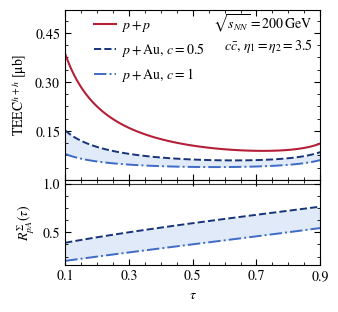

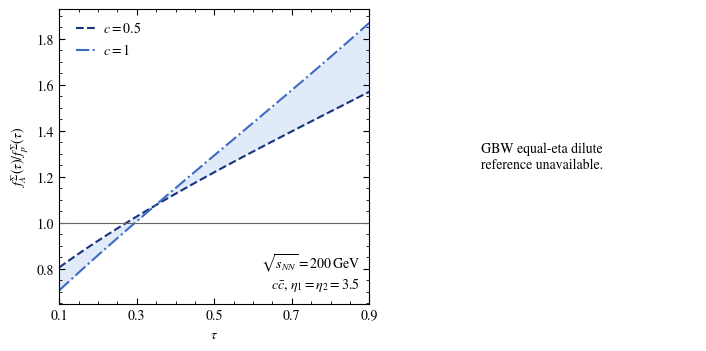

668

In [261]:
t0=time.time()
ANGULAR_REPS = run_angular_scan(CFG,CURVE_DENSITIES,BETA_GRID,
                               power=CURVE_POWER,replicas=CURVE_REPLICAS,
                               seed=CURVE_SEED,models=MODELS,progress=True)
print(f'Pointwise angular scan: {time.time()-t0:.1f} s')

# Normalize each target by the full TEEC integral, 0 <= tau <= 1.
# Integrating the regular beta density includes both endpoints without dividing
# by the vanishing tau Jacobian there.
CURVE_TOTAL_REPS = simpson(ANGULAR_REPS,x=BETA_GRID,axis=-1)
CURVE_TOTAL,CURVE_TOTAL_SEM = mean_sem(CURVE_TOTAL_REPS)
if np.any(~np.isfinite(CURVE_TOTAL_REPS)) or np.any(CURVE_TOTAL_REPS<=0):
    raise ValueError('Angular integral has no finite positive support; check cuts and curve precision.')
POINT_REPS = ANGULAR_REPS[:,:,TAU_INTERIOR]/TAU_JACOBIAN[None,None,:]
DIFF,DIFF_SEM = mean_sem(POINT_REPS)
# Retain the displayed-window integral only for diagnostics.
SHAPE_WINDOW_REPS = simpson(ANGULAR_REPS[:,:,SHAPE_BETA_MASK],
                            x=BETA_GRID[SHAPE_BETA_MASK],axis=-1)
SHAPE_WINDOW,SHAPE_WINDOW_SEM = mean_sem(SHAPE_WINDOW_REPS)
SHAPE = DIFF/CURVE_TOTAL[:,None]
SHAPE_REPS = POINT_REPS/CURVE_TOTAL_REPS[:,:,None]
_,SHAPE_SEM = mean_sem(SHAPE_REPS)
# Preserve the explicit full-range export names as aliases of the primary shapes.
FULL_MODEL_SHAPE = SHAPE
FULL_MODEL_SHAPE_REPS = SHAPE_REPS
FULL_MODEL_SHAPE_SEM = SHAPE_SEM
WINDOW_FRACTION,WINDOW_FRACTION_SEM = ratio_mean_sem(SHAPE_WINDOW_REPS,CURVE_TOTAL_REPS)
shape_areas = simpson(ANGULAR_REPS/CURVE_TOTAL_REPS[:,:,None],
                      x=BETA_GRID,axis=-1)
assert np.allclose(shape_areas,1,rtol=2e-12,atol=2e-12), 'Full-range shapes must integrate to one.'
SHAPE_NORMALIZATION = pd.DataFrame(dict(density=CURVE_DENSITIES,
    normalization='full_range_model',
    tau_min=0.0,tau_max=1.0,plot_tau_min=tau_lo,plot_tau_max=tau_hi,
    normalization_integral_per_area=CURVE_TOTAL,
    normalization_integral_SEM=CURVE_TOTAL_SEM,
    window_integral_per_area=SHAPE_WINDOW,window_integral_SEM=SHAPE_WINDOW_SEM,
    full_range_model_integral_per_area=CURVE_TOTAL,
    full_range_model_integral_SEM=CURVE_TOTAL_SEM,
    fraction_in_window=WINDOW_FRACTION,fraction_in_window_SEM=WINDOW_FRACTION_SEM,
    max_replica_area_error=np.max(abs(shape_areas-1),axis=0)))
SHAPE_NORMALIZATION.to_csv(OUTPUT/'shape_normalization.csv',index=False)
display(SHAPE_NORMALIZATION)
# Compare direct angle intergation to computeing TEEC and then inteover tau.
closure = pd.DataFrame(dict(density=CURVE_DENSITIES,
    integrated_pointwise=CURVE_TOTAL,pointwise_SEM=CURVE_TOTAL_SEM,
    integrated_reference=RATE[CURVE_INDICES],reference_SEM=RATE_SEM[CURVE_INDICES],
    relative_difference=CURVE_TOTAL/RATE[CURVE_INDICES]-1))
closure.to_csv(OUTPUT/'continuum_normalization_check.csv',index=False)
display(closure)

GEV2_TO_MICROBARN=389.3793656  # 1 GeV^-2 in microbarn
per_nucleon = GEV2_TO_MICROBARN*S_P/CURVE_DENSITIES[:,None]
TEEC_PER_NUCLEON=per_nucleon*DIFF
TEEC_PER_NUCLEON_SEM=per_nucleon*DIFF_SEM
NUCLEAR=[]; R_DIFF=[]; R_DIFF_SEM=[]; SHAPE_RATIO=[]; SHAPE_RATIO_SEM=[]
FULL_MODEL_SHAPE_RATIO=[]; FULL_MODEL_SHAPE_RATIO_SEM=[]
for i,(c,j) in enumerate(zip(C_VALUES,IA),1):
    rho=DENSITIES[j]
    rp=RATE[j]/(rho*RATE[IP])
    _,rp_sem=mean_sem(MAIN['rates'][:,j]/(rho*MAIN['rates'][:,IP]))
    rd,rd_sem=ratio_mean_sem(POINT_REPS[:,i,:],rho*POINT_REPS[:,0,:])
    sr=safe_divide(SHAPE[i],SHAPE[0])
    _,sr_sem=ratio_mean_sem(SHAPE_REPS[:,i,:],SHAPE_REPS[:,0,:])
    R_DIFF.append(rd); R_DIFF_SEM.append(rd_sem)
    SHAPE_RATIO.append(sr); SHAPE_RATIO_SEM.append(sr_sem)
    full_sr=safe_divide(FULL_MODEL_SHAPE[i],FULL_MODEL_SHAPE[0])
    _,full_sr_sem=ratio_mean_sem(FULL_MODEL_SHAPE_REPS[:,i,:],FULL_MODEL_SHAPE_REPS[:,0,:])
    FULL_MODEL_SHAPE_RATIO.append(full_sr); FULL_MODEL_SHAPE_RATIO_SEM.append(full_sr_sem)
    window_rp,window_rp_sem=ratio_mean_sem(SHAPE_WINDOW_REPS[:,i],rho*SHAPE_WINDOW_REPS[:,0])
    NUCLEAR.append(dict(c=c,A=A,Qs2_multiplier=rho,
                        integrated_RpA_weighted=rp,numerical_SEM=rp_sem,
                        window_integrated_RpA_weighted=float(window_rp),
                        window_integrated_RpA_SEM=float(window_rp_sem),
                        shape_tau_min=0.0,shape_tau_max=1.0,
                        plot_tau_min=tau_lo,plot_tau_max=tau_hi,
                        Sigma_p_GeV_minus2=S_P*RATE[IP],
                        Sigma_A_GeV_minus2=S_P*A**(2/3)/c*RATE[j],
                        fraction_tau_lt_01=DIAGNOSTICS.loc[j,'tau_below_01'],
                        mean_tau=DIAGNOSTICS.loc[j,'mean_tau']))
NUCLEAR=pd.DataFrame(NUCLEAR)
display(NUCLEAR)
NUCLEAR.to_csv(OUTPUT/'nuclear_summary.csv',index=False)

names=['pp']+[f'{NUCLEAR_LABEL}_c{c:g}' for c in C_VALUES]
tables=[pd.DataFrame(dict(target=name,tau=TAU_VALUES,density_per_area=DIFF[i],
                          density_numerical_SEM=DIFF_SEM[i],
                          teec_per_nucleon_microbarn=TEEC_PER_NUCLEON[i],
                          teec_per_nucleon_numerical_SEM=TEEC_PER_NUCLEON_SEM[i],
                          normalized_shape=SHAPE[i],shape_numerical_SEM=SHAPE_SEM[i],
                          shape_tau_min=0.0,shape_tau_max=1.0,
                          plot_tau_min=tau_lo,plot_tau_max=tau_hi,
                          shape_in_window=np.ones_like(TAU_VALUES,dtype=bool),
                          point_in_plot_range=SHAPE_TAU_MASK,
                          full_range_model_normalized_shape=FULL_MODEL_SHAPE[i],
                          full_range_model_shape_SEM=FULL_MODEL_SHAPE_SEM[i]))
        for i,name in enumerate(names)]
pd.concat(tables,ignore_index=True).to_csv(OUTPUT/'teec_tau_continuum.csv',index=False)
ratios=[pd.DataFrame(dict(c=c,tau=TAU_VALUES,RpA_weighted=R_DIFF[i],
                         RpA_numerical_SEM=R_DIFF_SEM[i],normalized_shape_ratio=SHAPE_RATIO[i],
                         shape_ratio_numerical_SEM=SHAPE_RATIO_SEM[i],
                         shape_tau_min=0.0,shape_tau_max=1.0,
                         plot_tau_min=tau_lo,plot_tau_max=tau_hi,
                         full_range_model_shape_ratio=FULL_MODEL_SHAPE_RATIO[i],
                         full_range_model_shape_ratio_SEM=FULL_MODEL_SHAPE_RATIO_SEM[i]))
        for i,c in enumerate(C_VALUES)]
pd.concat(ratios,ignore_index=True).to_csv(OUTPUT/'nuclear_tau_ratios.csv',index=False)
np.savez_compressed(OUTPUT/'replica_results.npz',rates=MAIN['rates'],densities=DENSITIES,
                    beta=BETA_GRID,angular_density=ANGULAR_REPS,curve_densities=CURVE_DENSITIES,
                    tau=TAU_VALUES,pointwise_density=POINT_REPS,
                    shape_normalization_range=np.array(SHAPE_NORMALIZATION_RANGE),
                    shape_normalization_integrals=CURVE_TOTAL_REPS,
                    tau_plot_range=np.array(TAU_PLOT_RANGE),
                    shape_window_integrals=SHAPE_WINDOW_REPS,
                    full_range_model_integrals=CURVE_TOTAL_REPS,
                    config_json=json.dumps(json_ready(asdict(CFG)),allow_nan=False))

# Publication layout: physical size is chosen for two side-by-side subfigures.
from matplotlib.ticker import AutoMinorLocator, ScalarFormatter, MaxNLocator
from matplotlib import font_manager
from matplotlib.backends.backend_pdf import PdfFile, RendererPdf
from io import BytesIO
import matplotlib as mpl

# Match the notes' Latin Modern text when the local TeX fonts are available.
lm_dir=Path('/Library/TeX/Root/texmf-dist/fonts/opentype/public/lm')
for filename in ['lmroman12-regular.otf','lmroman12-bold.otf','lmroman12-italic.otf']:
    font_file=lm_dir/filename
    if font_file.is_file(): font_manager.fontManager.addfont(str(font_file))
lm_regular=lm_dir/'lmroman12-regular.otf'
PLOT_FONT_FAMILY=(font_manager.FontProperties(fname=str(lm_regular)).get_name()
                  if lm_regular.is_file() else 'STIXGeneral')
# The manuscript uses Times-style text; the original plots keep Latin Modern.
if paper:
    termes_dir=Path('/Library/TeX/Root/texmf-dist/fonts/opentype/public/tex-gyre')
    for suffix in ('regular','bold','italic','bolditalic'):
        font_file=termes_dir/f'texgyretermes-{suffix}.otf'
        if font_file.is_file(): font_manager.fontManager.addfont(str(font_file))
    termes_regular=termes_dir/'texgyretermes-regular.otf'
    PLOT_FONT_FAMILY=(font_manager.FontProperties(fname=str(termes_regular)).get_name()
                      if termes_regular.is_file() else 'STIXGeneral')
PLOT_STYLE={'font.family':PLOT_FONT_FAMILY,'mathtext.fontset':'stix' if paper else 'cm',
    'font.size':ACTIVE_PLOT_FONT_SIZE,'axes.labelsize':ACTIVE_PLOT_FONT_SIZE,
    'axes.titlesize':ACTIVE_PLOT_FONT_SIZE,'figure.titlesize':ACTIVE_PLOT_FONT_SIZE,
    'xtick.labelsize':ACTIVE_PLOT_FONT_SIZE,'ytick.labelsize':ACTIVE_PLOT_FONT_SIZE,
    'legend.fontsize':ACTIVE_PLOT_FONT_SIZE,'legend.title_fontsize':ACTIVE_PLOT_FONT_SIZE,
    'axes.linewidth':.8,'savefig.dpi':300,
    'axes.spines.top':True,'axes.spines.right':True,
    'xtick.direction':'in','ytick.direction':'in'}
visible=(TAU_VALUES>=tau_lo-1e-12)&(TAU_VALUES<=tau_hi+1e-12)
x=TAU_VALUES[visible]
pp_color='#b42038'
blue=['#17347a','#3e6bc5','#225591','#6984b3']
styles=['--','-.',':','--']
A_label=rf'$p+\mathrm{{{CFG.nucleus}}}$'
energy_value=CFG.sqrt_s/1000 if CFG.sqrt_s>=1000 else CFG.sqrt_s
energy_unit='TeV' if CFG.sqrt_s>=1000 else 'GeV'
energy_line=rf'$\sqrt{{s_{{NN}}}}={energy_value:g}\,\mathrm{{{energy_unit}}}$'
qname='c' if CFG.quark=='charm' else 'b' if CFG.quark=='bottom' else 'Q'
pair_line=rf'${qname}\bar{{{qname}}}$'
eta_line=(rf'$\eta_1=\eta_2={CFG.eta1:g}$' if CFG.eta1==CFG.eta2
          else rf'$\eta_1={CFG.eta1:g},\ \eta_2={CFG.eta2:g}$')
kinematic_note='\n'.join([energy_line,f'{pair_line}, {eta_line}'])

def finish_axis(axis):
    axis.xaxis.set_minor_locator(AutoMinorLocator(4))
    axis.yaxis.set_minor_locator(AutoMinorLocator(4))
    axis.tick_params(which='both',top=True,right=True)
    axis.tick_params(which='major',length=4)
    axis.tick_params(which='minor',length=2)

def fit_teec_yaxis_notation(axis):
    """Use regular numbers unless the y-axis would be clipped in PNG or PDF."""
    figure=axis.figure
    formatter=ScalarFormatter(useMathText=True,useOffset=False)
    formatter.set_scientific(False)
    axis.yaxis.set_major_formatter(formatter)
    original_dpi=figure.dpi
    save_dpi=mpl.rcParams['savefig.dpi']
    save_dpi=original_dpi if save_dpi=='figure' else float(save_dpi)

    def labels_fit(renderer):
        bounds=axis.yaxis.get_tightbbox(renderer)
        if bounds is None:
            return True
        # Leave one point for antialiasing at the canvas edge.
        pad=figure.dpi/72
        canvas=figure.bbox
        return (bounds.x0>=canvas.x0+pad and bounds.y0>=canvas.y0+pad
                and bounds.x1<=canvas.x1-pad and bounds.y1<=canvas.y1-pad)

    try:
        # Measure at the actual PNG export resolution.
        figure.set_dpi(save_dpi)
        figure.canvas.draw()
        regular_fits=labels_fit(figure.canvas.get_renderer())
        if regular_fits:
            # Vector output uses point units and its own font metrics.
            figure.set_dpi(72)
            with BytesIO() as buffer:
                pdf_file=PdfFile(buffer)
                try:
                    width,height=figure.get_size_inches()
                    pdf_file.newPage(width,height)
                    renderer=RendererPdf(pdf_file,save_dpi,height,width)
                    figure.draw(renderer)
                    regular_fits=labels_fit(renderer)
                    renderer.finalize()
                    pdf_file.finalize()
                finally:
                    pdf_file.close()
        if not regular_fits:
            formatter.set_scientific(True)
            formatter.set_powerlimits((0,0))
        return 'regular' if regular_fits else 'scientific'
    finally:
        figure.set_dpi(original_dpi)

def save_plot(figure,stem):
    # Preserve the requested physical width; no tight bounding-box resizing.
    if paper:
        original_dpi=figure.dpi
        try:
            # Resolve the legend at the actual raster-export scale.
            # The extra draw keeps PNG and PDF legend spacing consistent.
            figure.set_dpi(300)
            figure.canvas.draw()
            figure.savefig(OUTPUT/f'{stem}.png',dpi=300)
            figure.savefig(OUTPUT/f'{stem}.pdf')
        finally:
            figure.set_dpi(original_dpi)
    else:
        figure.savefig(OUTPUT/f'{stem}.png')
        figure.savefig(OUTPUT/f'{stem}.pdf')

def paper_legend(axis, main_teec=False):
    """Keep paper legends inside the axes, in the space freed by the model label."""
    return axis.legend(loc='upper left',bbox_to_anchor=(.09 if main_teec else .035,.98),
                       frameon=False,handlelength=1.6,handletextpad=.4,
                       borderpad=.2,borderaxespad=.2,ncol=1)

def draw_shape(axis):
    if len(C_VALUES)>1:
        band=np.asarray(SHAPE_RATIO)[:,visible]
        axis.fill_between(x,np.min(band,axis=0),np.max(band,axis=0),
                          color='#6d9cdf',alpha=.21,linewidth=0)
    for i,c in enumerate(C_VALUES):
        axis.plot(x,SHAPE_RATIO[i][visible],color=blue[i%len(blue)],
                  ls=styles[i%len(styles)],lw=1.5,label=f'$c={c:g}$')
    axis.axhline(1,color='.4',lw=.8)
    axis.set(xlabel=r'$\tau$',ylabel=r'$f^\Sigma_A(\tau)/f^\Sigma_p(\tau)$',xlim=TAU_PLOT_RANGE)
    axis.set_xticks(np.linspace(tau_lo,tau_hi,5))
    axis.text(.97,.035,kinematic_note,
              ha='right',va='bottom',transform=axis.transAxes,linespacing=1.1)
    if paper:
        paper_legend(axis)
    else:
        axis.text(.04,.97,CFG.target_model,ha='left',va='top',transform=axis.transAxes)
        axis.legend(loc='upper left',bbox_to_anchor=(0,.88),frameon=False,handlelength=1.6,
                    handletextpad=.4,borderpad=.2)
    finish_axis(axis)

def draw_density(axis):
    if DILUTE_REFERENCE_AVAILABLE:
        axis.errorbar(DENSITIES,RATE/DILUTE,yerr=RATE_SEM/DILUTE,
                      fmt='o-',color=blue[0],lw=1.2,markersize=3.5)
        axis.axhline(1,color='.4',ls='--',lw=.8)
        axis.set(xlabel=r'Density multiplier $\rho$',
                 ylabel=r'$\Sigma_{\mathrm{full}}/\Sigma_{\mathrm{dilute}}$',xscale='log')
        axis.text(.04,.04,'\n'.join([kinematic_note,'Full-range LO model']),
                  ha='left',va='bottom',transform=axis.transAxes,linespacing=1.1)
        axis.tick_params(which='both',top=True,right=True)
        axis.yaxis.set_minor_locator(AutoMinorLocator(4))
    else:
        axis.axis('off')
        axis.text(.5,.5,'GBW equal-eta dilute\nreference unavailable.',
                  ha='center',va='center',transform=axis.transAxes)

with mpl.rc_context(PLOT_STYLE):
    fig,ax=plt.subplots(2,1,sharex=True,figsize=(ACTIVE_PLOT_WIDTH_IN,ACTIVE_PLOT_WIDTH_IN),
                        gridspec_kw={'height_ratios':[2,1],'hspace':0},layout=None)
    # Equal horizontal/vertical span makes the joined axes square. Explicit
    # margins avoid the gap that automatic layout reserves between subplots.
    fig.subplots_adjust(left=.20,right=.95,bottom=.17,top=.92,hspace=0)
    if len(C_VALUES)>1:
        nuclear=TEEC_PER_NUCLEON[1:,visible]
        ax[0].fill_between(x,np.min(nuclear,axis=0),np.max(nuclear,axis=0),
                           color='#6d9cdf',alpha=.21,linewidth=0)
        rr=np.asarray(R_DIFF)[:,visible]
        ax[1].fill_between(x,np.min(rr,axis=0),np.max(rr,axis=0),
                           color='#6d9cdf',alpha=.21,linewidth=0)
    ax[0].plot(x,TEEC_PER_NUCLEON[0,visible],color=pp_color,lw=1.5,label=r'$p+p$')
    for i,c in enumerate(C_VALUES):
        style=dict(color=blue[i%len(blue)],ls=styles[i%len(styles)],lw=1.4)
        ax[0].plot(x,TEEC_PER_NUCLEON[i+1,visible],label=f'{A_label}, $c={c:g}$',**style)
        ax[1].plot(x,R_DIFF[i][visible],**style)
    ax[0].set_ylabel(r'$\mathrm{TEEC}^{h+h}\ [\mathrm{\mu b}]$')
    ax[0].yaxis.set_major_locator(MaxNLocator(nbins=4,prune='lower'))
    ax[0].set_ylim(bottom=0,top=1.35*np.max(TEEC_PER_NUCLEON[:,visible]))
    if paper:
        paper_legend(ax[0],main_teec=True)
    else:
        ax[0].legend(loc='upper right',bbox_to_anchor=(.98,.70),frameon=False,handlelength=1.6,
                     handletextpad=.4,borderpad=.2)
    ax[0].text(.97,.98,kinematic_note,ha='right',va='top',
               transform=ax[0].transAxes,linespacing=1.1)
    if not paper:
        ax[0].text(.025,.98,CFG.target_model,
                   ha='left',va='top',transform=ax[0].transAxes)
    ax[1].axhline(1,color='.22',lw=.8,zorder=0)
    ax[1].set(xlabel=r'$\tau$',ylabel=r'$R_{pA}^{\Sigma}(\tau)$',xlim=TAU_PLOT_RANGE)
    ax[1].set_xticks(np.linspace(tau_lo,tau_hi,5))
    for a in ax: finish_axis(a)
    ax[0].tick_params(labelbottom=False)
    TEEC_Y_NOTATION=fit_teec_yaxis_notation(ax[0])
    save_plot(fig,'teec_saturation')
    plt.show()

    # Combined overview is intended to occupy the full manuscript text width.
    fig,ax=plt.subplots(1,2,figsize=(2*ACTIVE_PLOT_WIDTH_IN+.15,ACTIVE_PLOT_WIDTH_IN),layout='constrained')
    draw_shape(ax[0]);draw_density(ax[1])
    save_plot(fig,'shape_and_dilute_control')
    plt.show()

    # These standalone files are sized for individual side-by-side subfigures.
    for stem,draw in [('teec_shape_ratio',draw_shape),('teec_density_control',draw_density)]:
        fig,axis=plt.subplots(figsize=(ACTIVE_PLOT_WIDTH_IN,ACTIVE_PLOT_WIDTH_IN),layout='constrained')
        draw(axis)
        save_plot(fig,stem)
        plt.close(fig)

(OUTPUT/'publication_style.json').write_text(json.dumps(dict(
    paper=bool(paper),legend_placement='inside_axes' if paper else 'original',
    target_model_label=not paper,
    font_family=PLOT_FONT_FAMILY,font_size_pt=ACTIVE_PLOT_FONT_SIZE,
    standalone_width_inches=ACTIVE_PLOT_WIDTH_IN,standalone_height_inches=ACTIVE_PLOT_WIDTH_IN,
    joined_panel_gap=0,joined_panel_height_ratios=[2,1],
    combined_width_inches=2*ACTIVE_PLOT_WIDTH_IN+.15,
    units='upright math roman',vector_format='pdf',
    teec_y_notation_policy='regular_if_fits_else_scientific',
    teec_y_notation=TEEC_Y_NOTATION,
    usage=('Insert standalone paper figures at about 3.4 inches wide (one column or half a full-width figure) '
           'for approximately 10-point text; combined figures span the full text width.' if paper else
           'Use standalone files at about 0.485 textwidth each; combined figures span the full text width.')),indent=2))


## 13. Optional convergence and independent checks

Set `RUN_CONVERGENCE_CHECKS=True` in Section 1 to run the checks below. Sobol convergence and proposal invariance use the selected providers. The Gaussian quadrature and first-density reference run only when applicable. Three representative interior angular points are checked; they do not assert accuracy at every endpoint or for every future model.

In [262]:
if RUN_CONVERGENCE_CHECKS:
    PRIMARY_DENSITIES=np.r_[1.0,np.array(C_VALUES)*A**(1/3)]
    CONV=[]
    for power in sorted(set([max(8,POWER-4),max(10,POWER-2),POWER])):
        check=run_scan(CFG,PRIMARY_DENSITIES,power=power,replicas=8,seed=8071)
        cm,cs=mean_sem(check['rates'])
        row=dict(power=power,points_per_scramble=2**power,pp_rate=cm[0],pp_SEM=cs[0])
        row.update({f'RpA_c{c:g}':cm[i]/(PRIMARY_DENSITIES[i]*cm[0]) for i,c in enumerate(C_VALUES,1)})
        CONV.append(row)
    CONV=pd.DataFrame(CONV); display(CONV)
    CONV.to_csv(OUTPUT/'convergence.csv',index=False)
    
    # Weak-density integral must approach the independent analytic coefficient.
    if DILUTE_REFERENCE_AVAILABLE:
        assert abs(RATE[0]/DILUTE[0]-1)<0.02
        print('Weak-density full / first-density reference:',RATE[0]/DILUTE[0])
    
    # Change the importance proposal without changing the physics.
    proposal_check=run_scan(CFG,PRIMARY_DENSITIES,power=max(10,POWER-1),replicas=8,
                            seed=9701,proposal_multiplier=1.5)
    pc,pc_se=mean_sem(proposal_check['rates'])
    ref=RATE[[IP]+IA]; ref_se=RATE_SEM[[IP]+IA]
    proposal_z=np.abs(pc-ref)/np.sqrt(pc_se**2+ref_se**2)
    print('Proposal-invariance differences in combined numerical SEM:',proposal_z)
    assert np.max(proposal_z)<6
    
    if GBW_REFERENCE_AVAILABLE:
        # Compare selected pointwise values with independent Gaussian quadrature.
        QUAD=[]
        for j,tau_test in [(0,0.25),(0,0.75),(len(CURVE_DENSITIES)-1,0.50)]:
            i=int(np.argmin(abs(TAU_VALUES-tau_test)))
            phi=np.pi-BETA_GRID[TAU_INTERIOR][i]
            rho=CURVE_DENSITIES[j]
            coarse=fixed_phi_quadrature(phi,rho,CFG,radial_order=96,hermite_order=24)/TAU_JACOBIAN[i]
            refined=fixed_phi_quadrature(phi,rho,CFG,radial_order=128,hermite_order=32)/TAU_JACOBIAN[i]
            delta=abs(refined-coarse)
            QUAD.append(dict(density=rho,tau=TAU_VALUES[i],QMC=DIFF[j,i],
                             QMC_SEM=DIFF_SEM[j,i],quadrature=refined,
                             quadrature_refinement_difference=delta,
                             discrepancy_in_SEM=abs(DIFF[j,i]-refined)/max(DIFF_SEM[j,i],delta,1e-15)))
        QUAD=pd.DataFrame(QUAD); display(QUAD)
        QUAD.to_csv(OUTPUT/'independent_quadrature.csv',index=False)
        assert QUAD['discrepancy_in_SEM'].max()<6
    else:
        print('GBW-specific quadrature skipped for the selected target.')
    print('Passed: convergence run, proposal invariance and applicable independent references.')
else:
    print('Optional convergence checks disabled in Section 1.')

Optional convergence checks disabled in Section 1.


## 14. Optional kinematic and PDF comparisons

`RUN_APPROXIMATION_CHECKS=True` generates just two additional continuous-$\tau$ plots:

- $100\,[R_{pA}^{\mathrm{exact}}/R_{pA}^{\mathrm{eik}}-1]$, holding `CFG.xt_max` fixed.
- $100\,[R_{pA}(x_{t,\max}=1)/R_{pA}(x_{t,\max}=0.01)-1]$, holding `CFG.kinematics` fixed.

The two cuts in the small-x check are fixed at `1.0` and `0.01`, regardless of `OBSERVABLE['xt_max']`, `OVERRIDES['xt_max']` or the resolved `CFG.xt_max`. The selected main cut is still used for the main TEEC and the exact/eikonal comparison.

For `MV`, the small-x comparison uses a **frozen initial condition** for $x_t>x_0=0.01$ by default (`x_above_x0="freeze"`). That region is a diagnostic continuation, not a BK prediction. `"error"` rejects it and therefore disables the possibility of the full-$x_t$ comparison.

Each curve corresponds to a value in `C_VALUES`. These compare the differential $R_{pA}$ from the TEEC, without unit-area normalization. The square format, fonts, interior $\tau$ range and in-plot kinematics match the main figures. PNG/PDF figures, percentage-difference CSV tables, replica arrays and settings are saved in `OUTPUT`.

The angular scans use `CURVE_POWER`, `CURVE_REPLICAS` and a common `CURVE_SEED`; identical configurations reuse curves. Numerical uncertainties retain correlations between matching scrambles. The full-angle integrated check table also retains the toy-PDF variations and the low-energy diagnostic. That diagnostic excludes parents with small longitudinal momentum in the selected pseudorapidity frame; it is not an experimental hadron selection.

In [263]:
# Compare the differential nuclear ratios, without unit-area normalization.
def comparison_config_key(cfg):
    return json.dumps(json_ready(asdict(cfg)),sort_keys=True,allow_nan=False)


def fixed_xt_cut_configs(cfg):
    """Always compare xt_max=1 to 0.01, independently of the main cfg.xt_max."""
    return [replace(cfg,xt_max=cut) for cut in (1.0,0.01)]


def summarize_comparison(angular,densities):
    point=angular[:,:,TAU_INTERIOR]/TAU_JACOBIAN[None,None,:]
    rp=[];rp_sem=[];rp_reps=[]
    for i,rho in enumerate(densities[1:],1):
        value,error=ratio_mean_sem(point[:,i],rho*point[:,0])
        rp.append(value);rp_sem.append(error)
        rp_reps.append(safe_divide(point[:,i],rho*point[:,0]))
    return dict(rp=np.asarray(rp),rp_sem=np.asarray(rp_sem),
                rp_reps=np.stack(rp_reps,axis=1))


def comparison_percent(numerator,denominator):
    # Central values use ratios of mean densities, as in the main RpA plot.
    # Pair identical Sobol scrambles to retain correlations in the uncertainty.
    percent=100*(safe_divide(numerator['rp'],denominator['rp'])-1)
    _,sem=ratio_mean_sem(numerator['rp_reps'],denominator['rp_reps'])
    return percent,100*sem


def plot_comparison(percent,stem,ylabel):
    """One square percentage-difference plot, using the main figure style."""
    with mpl.rc_context(PLOT_STYLE):
        fig,axis=plt.subplots(figsize=(ACTIVE_PLOT_WIDTH_IN,ACTIVE_PLOT_WIDTH_IN),layout='constrained')
        if len(C_VALUES)>1:
            band=np.asarray(percent)[:,visible]
            axis.fill_between(x,np.min(band,axis=0),np.max(band,axis=0),
                              color='#6d9cdf',alpha=.21,linewidth=0)
        for i,c in enumerate(C_VALUES):
            axis.plot(x,percent[i,visible],color=blue[i%len(blue)],
                      ls=styles[i%len(styles)],lw=1.5,label=f'$c={c:g}$')
        axis.axhline(0,color='.4',lw=.8,zorder=0)
        axis.set(xlabel=r'$\tau$',ylabel=ylabel,xlim=TAU_PLOT_RANGE)
        axis.set_xticks(np.linspace(tau_lo,tau_hi,5))
        axis.ticklabel_format(axis='y',style='plain',useOffset=False)
        axis.yaxis.set_major_locator(MaxNLocator(nbins=5))
        low=min(0,float(np.nanmin(percent[:,visible])))
        high=max(0,float(np.nanmax(percent[:,visible])))
        span=max(high-low,.01)
        axis.set_ylim(low-.12*span,high+span)
        if paper:
            paper_legend(axis)
        else:
            axis.legend(loc='upper left',bbox_to_anchor=(.02,.65),frameon=False,handlelength=1.6,
                        handletextpad=.4,borderpad=.2)
        axis.text(.97,.98,kinematic_note,
                  ha='right',va='top',transform=axis.transAxes,linespacing=1.1)
        if not paper:
            axis.text(.025,.98,CFG.target_model,
                      ha='left',va='top',transform=axis.transAxes)
        finish_axis(axis)
        save_plot(fig,stem)
        plt.show()


if RUN_APPROXIMATION_CHECKS:
    PRIMARY_DENSITIES=np.r_[1.0,np.array(C_VALUES)*A**(1/3)]
    # The first configuration is the numerator; the second is the denominator.
    # The xt comparison always uses 1 and 0.01; CFG.xt_max is ignored there.
    # The kinematics comparison uses CFG.xt_max for both exact and eikonal modes.
    COMPARISONS=[
        dict(stem='teec_xt_max_comparison',
             labels=[r'$x_{t,\max}=1$',r'$x_{t,\max}=0.01$'],
             configs=fixed_xt_cut_configs(CFG),
             fixed_note=f'{CFG.kinematics.capitalize()} kinematics',
             ylabel=r'$R_{pA}^{x_{t,\max}=1} / R_{pA}^{x_{t,\max}=0.01} -1 \ [\%]$'),
        dict(stem='teec_kinematics_comparison',labels=['Exact','Eikonal'],
             configs=[replace(CFG,kinematics='exact'),replace(CFG,kinematics='eikonal')],
             fixed_note=rf'$x_{{t,\max}}={CFG.xt_max:g}$',
             ylabel=r'$R_{pA}^{\mathrm{exact}} / R_{pA}^{\mathrm{eik}}-1 \ [\%]$'),
    ]
    check_variants=[('reference',CFG)]
    for comparison in COMPARISONS:
        check_variants += [(f"{comparison['stem']}: {label}",cfg)
                           for label,cfg in zip(comparison['labels'],comparison['configs'])]
    if CFG.pdf_name == 'toy':
        check_variants += [
            ('PDF softer x exponent',
             replace(CFG,pdf_options={**CFG.pdf_options,'lambda':.1,'beta':4.})),
            ('PDF steeper x exponent',
             replace(CFG,pdf_options={**CFG.pdf_options,'lambda':.3,'beta':6.})),
        ]
    if min(CFG.eta1,CFG.eta2)>0:
        check_variants += [('low-energy diagnostic cut',replace(CFG,
            p_min=max(CFG.p_min,5*CFG.mass/np.sinh(min(CFG.eta1,CFG.eta2)))))]
    CHECKS=[]
    rate_cache={}
    for name,cfg in check_variants:
        key=comparison_config_key(cfg)
        if key not in rate_cache:
            rate_cache[key]=run_scan(cfg,PRIMARY_DENSITIES,power=max(10,POWER-1),
                                     replicas=8,seed=5123)
        rr=rate_cache[key]
        rm,rs=mean_sem(rr['rates'])
        row=dict(variant=name,kinematics=cfg.kinematics,xt_max=cfg.xt_max,
                 pp_yield_per_area=rm[0],pp_SEM=rs[0])
        for i,c in enumerate(C_VALUES,1):
            value,error=ratio_mean_sem(rr['rates'][:,i],PRIMARY_DENSITIES[i]*rr['rates'][:,0])
            row[f'RpA_c{c:g}']=float(value)
            row[f'RpA_SEM_c{c:g}']=float(error)
        CHECKS.append(row)
    CHECKS=pd.DataFrame(CHECKS)
    display(CHECKS)
    CHECKS.to_csv(OUTPUT/'approximation_and_pdf_checks.csv',index=False)

    angular_cache={comparison_config_key(CFG):ANGULAR_REPS}
    summary_cache={}
    for comparison in COMPARISONS:
        results=[];replicas=[];metadata=[]
        for label,cfg in zip(comparison['labels'],comparison['configs']):
            key=comparison_config_key(cfg)
            if key not in angular_cache:
                print(f"Angular comparison: {cfg.kinematics}, xt_max={cfg.xt_max:g}",flush=True)
                angular_cache[key]=run_angular_scan(cfg,PRIMARY_DENSITIES,BETA_GRID,
                    power=CURVE_POWER,replicas=CURVE_REPLICAS,seed=CURVE_SEED,progress=True)
            if key not in summary_cache:
                summary_cache[key]=summarize_comparison(angular_cache[key],PRIMARY_DENSITIES)
            results.append(summary_cache[key]);replicas.append(angular_cache[key])
            metadata.append(dict(label=label,config=json_ready(asdict(cfg))))
        percent,percent_sem=comparison_percent(*results)
        tables=[pd.DataFrame(dict(c=c,tau=TAU_VALUES,
            RpA_numerator=results[0]['rp'][i],RpA_denominator=results[1]['rp'][i],
            relative_difference_percent=percent[i],numerical_SEM_percent=percent_sem[i]))
            for i,c in enumerate(C_VALUES)]
        stem=comparison['stem']
        pd.concat(tables,ignore_index=True).to_csv(OUTPUT/f'{stem}.csv',index=False)
        np.savez_compressed(OUTPUT/f'{stem}_replicas.npz',
            angular_density=np.stack(replicas),densities=PRIMARY_DENSITIES,
            beta=BETA_GRID,tau=TAU_VALUES)
        (OUTPUT/f'{stem}.json').write_text(json.dumps(dict(
            numerator=metadata[0],denominator=metadata[1],
            definition='100 * (RpA_numerator / RpA_denominator - 1)',
            normalization='differential RpA; no unit-area normalization',
            curve_power=CURVE_POWER,curve_replicas=CURVE_REPLICAS,
            curve_seed=CURVE_SEED,tau_plot_range=TAU_PLOT_RANGE,
            fixed_note=comparison['fixed_note']),indent=2))
        plot_comparison(percent,stem,comparison['ylabel'])
    print('Two percentage-comparison plots and numerical tables saved in',OUTPUT)
else:
    print('Optional approximation/PDF comparisons disabled in Section 1.')


Optional approximation/PDF comparisons disabled in Section 1.


## 15. Interpretation and provenance for the selected run

The integrated weighted nuclear modification corresponds to **paper Eq. (37)**. The linear-density expansion and dilute-scaling discussion are **Eqs. (38)-(40)**. The numerical GBW dilute control in notebook Section 9 is an auxiliary model-specific check, not a direct evaluation of the MV asymptote in paper Eq. (39).


In [264]:
pp_frac=DIAGNOSTICS.loc[IP,'tau_below_01']
texts=[]
for c,j in zip(C_VALUES,IA):
    nuc=NUCLEAR.loc[NUCLEAR.c==c].iloc[0]
    texts.append(f"- **{NUCLEAR_LABEL}, c={c:g}:** full-range LO-model integrated weighted R_pA = "
                 f"{nuc.integrated_RpA_weighted:.4f} +/- {nuc.numerical_SEM:.4f} "
                 f"(numerical only); window-integrated R_pA = {nuc.window_integrated_RpA_weighted:.4f} "
                 f"over tau=[{tau_lo:g}, {tau_hi:g}]; weighted fraction at tau<0.1 = "
                 f"{100*nuc.fraction_tau_lt_01:.1f}% (pp: {100*pp_frac:.1f}%).")
display(Markdown('\n'.join(texts)))
display(Markdown(
    'Each unit-area shape uses its own full-range TEEC integral over tau=[0, 1]. '
    'The displayed angular window does not set the shape denominator. '
    'Window-integrated weighted nuclear ratios remain available as diagnostics. '
    'The integrals are TEEC weighted, not unweighted pair counts or event cross sections. '
    'Interpret the results for the selected model and settings: target tails, PDF, '
    'soft radiation, tagging and acceptance require separate phenomenological assessment.'))
provenance=dict(RUN_INPUTS, python=platform.python_version(),numpy=np.__version__,
                target=CFG.target_model,pdf=CFG.pdf_name,
                proposal=effective_proposal(CFG,MODELS),tau_points=TAU_VALUES.tolist(),
                scope='cross-branch Q-Qbar pair counted once; fixed pseudorapidities',
                convergence_checks=RUN_CONVERGENCE_CHECKS,
                approximation_checks=RUN_APPROXIMATION_CHECKS)
(OUTPUT/'provenance.json').write_text(json.dumps(json_ready(provenance),indent=2,allow_nan=False))
print('Saved selected-run figures, tables, replicas and provenance to',OUTPUT)

- **pAu, c=0.5:** full-range LO-model integrated weighted R_pA = 0.4864 +/- 0.0001 (numerical only); window-integrated R_pA = 0.5449 over tau=[0.1, 0.9]; weighted fraction at tau<0.1 = 29.6% (pp: 41.2%).
- **pAu, c=1:** full-range LO-model integrated weighted R_pA = 0.2908 +/- 0.0001 (numerical only); window-integrated R_pA = 0.3366 over tau=[0.1, 0.9]; weighted fraction at tau<0.1 = 24.7% (pp: 41.2%).

Each unit-area shape uses its own full-range TEEC integral over tau=[0, 1]. The displayed angular window does not set the shape denominator. Window-integrated weighted nuclear ratios remain available as diagnostics. The integrals are TEEC weighted, not unweighted pair counts or event cross sections. Interpret the results for the selected model and settings: target tails, PDF, soft radiation, tagging and acceptance require separate phenomenological assessment.

Saved selected-run figures, tables, replicas and provenance to results/RHIC_charm_paper_MV_CT18NLO_CM_exact_89a7ae73
